# Pretrained Transfer Learning with Source Pretraining, Target Fine-Tuning, and Layer-wise PC Tracking

## Task Description
Implementation of a two-stage transfer learning pipeline based on Di et al. (2025):
1. **Target Fixed Subsets Setup**:
   - At initialization, draw and fix `SAMPLE_SIZES` instances from the target dataset `NUM_REPLICATIONS` times with fixed random seeds for reproducible target validation loss and layer-wise Projection Correlation (PC) evaluation with confidence intervals.
2. **Stage 1 (Source Pretraining)**:
   - Train a 6-layer CNN on the source dataset.
   - Early stopping on source validation loss with patience `EARLY_STOP_PATIENCE` (=5).
   - Upon trigger, run an extra `POST_EARLY_STOP_EPOCHS` (=10) control epochs.
   - At each epoch, evaluate and log: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC ($\omega_j$) with 95% CI.
   - Select best source model: by Source Val Loss or by PC generality.
3. **Stage 2 (Target Fine-Tuning across 7 Models $M_0 \dots M_6$)**:
   - Transfer first $k$ layers ($k \in \{0, 1, 2, 3, 4, 5, 6\}$).
   - Target training on fixed sample subset (`SAMPLE_SIZES`).
   - Early stopping monitored on Target Validation Loss with patience `TARGET_PATIENCE` (=5).
   - Log each epoch: Train Loss, Test Accuracy, Target Val Loss, Layer-wise PC.

## 1. Environment Setup, Google Colab Integration & GPU Verification

In [ ]:
import os
import sys
import time
import json
import glob
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


def setup_environment(seed: int = 42) -> Tuple[torch.device, int]:
    """Setup device, random seeds, and Google Colab environment / Drive mount.

    Parameters
    ----------
    seed : int
        Base random seed for reproducibility.

    Returns
    -------
    Tuple[torch.device, int]
        (device, seed) where device is cuda or cpu.
    """
    import random
    if "google.colab" in sys.modules:
        print("[Colab] Google Colab environment detected.")
        target_dir = None

        # 1. Check if repository is already in current working directory or /content/Di
        for path in [os.getcwd(), '/content/Di', '/content']:
            if os.path.exists(os.path.join(path, 'models.py')) and os.path.exists(os.path.join(path, 'di_algorithm.py')):
                target_dir = path
                break

        # 2. If not found, try searching in Google Drive
        if target_dir is None:
            try:
                from google.colab import drive
                drive.mount('/content/drive')
                candidates = [
                    '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di',
                    '/content/drive/MyDrive/Diplom/var1_Di/code/Di',
                    '/content/drive/MyDrive/var1_Di/code/Di',
                    '/content/drive/MyDrive/code/Di',
                    '/content/drive/MyDrive/Di',
                ]
                for cand in candidates:
                    if os.path.isdir(cand) and os.path.exists(os.path.join(cand, 'models.py')):
                        target_dir = cand
                        break

                if target_dir is None and os.path.isdir('/content/drive/MyDrive'):
                    print("[Colab] Searching for project folder in Google Drive...")
                    for root, dirs, files in os.walk('/content/drive/MyDrive'):
                        if 'models.py' in files and 'di_algorithm.py' in files:
                            target_dir = root
                            break
            except Exception as e:
                print(f"[Colab] Google Drive search skipped/failed: {e}")

        # 3. If still not found, clone repository directly from GitHub
        if target_dir is None:
            print("[Colab] Repository files not found locally or in Drive. Cloning from GitHub...")
            import subprocess
            subprocess.run(['git', 'clone', 'https://github.com/DR24DR24/Di.git', '/content/Di'], check=False)
            if os.path.exists('/content/Di/models.py'):
                target_dir = '/content/Di'

        if target_dir:
            os.chdir(target_dir)
            if target_dir not in sys.path:
                sys.path.insert(0, target_dir)
            print(f"[Colab] Working directory set to: {os.getcwd()}")
        else:
            cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
            if cd not in sys.path:
                sys.path.insert(0, cd)
            print(f"[Colab] WARNING: 'models.py' not found! Current directory: {os.getcwd()}")
    else:
        cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
        if cd not in sys.path:
            sys.path.insert(0, cd)
        print(f"[Local] Working directory: {os.getcwd()}")

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Device: {device}")
    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Random seed fixed: {seed}")
    return device, seed


# Execute environment setup immediately when Cell 3 runs
device, seed = setup_environment(seed=42)


[Colab] Google Colab environment detected.
Mounted at /content/drive
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cpu
Random seed fixed: 42


## 2. Experiment Parameters, Named Constants & Output Directory

In [ ]:
def get_timestamp() -> str:
    """Return a compact timestamp string YYYYMMDD_HHMMSS."""
    return datetime.now().strftime("%Y%m%d_%H%M%S")


def make_result_path(base_name: str, ext: str, ts: Optional[str] = None, results_dir: Optional[str] = None) -> str:
    """Generate a full output file path with timestamp in the results directory."""
    if ts is None:
        ts = get_timestamp()
    filename = f"{base_name}_{ts}.{ext}"
    if results_dir is None:
        results_dir = os.path.join(os.getcwd(), "pretrained")
    os.makedirs(results_dir, exist_ok=True)
    return os.path.join(results_dir, filename)


def get_experiment_params(
    experiment_case: str = 'imbalance',
    sample_sizes: Optional[List[int]] = None,
    num_replications: int = 10,
    use_real_cifar10: bool = True,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    ft_sample_size: Optional[int] = 1000,
    best_model_criterion: str = 'pc',
    notebook_name: str = "pretrained",
    seed: int = 42,
) -> Dict[str, Any]:
    """Return all experiment parameters as a dictionary."""
    if sample_sizes is None:
        sample_sizes = [200]

    results_dir = os.path.join(os.getcwd(), notebook_name)
    os.makedirs(results_dir, exist_ok=True)

    params = {
        "EXPERIMENT_CASE": experiment_case,
        "SAMPLE_SIZES": sample_sizes,
        "NUM_REPLICATIONS": num_replications,
        "USE_REAL_CIFAR10": use_real_cifar10,
        "PRETRAIN_EPOCHS": pretrain_epochs,
        "EARLY_STOP_PATIENCE": early_stop_patience,
        "POST_EARLY_STOP_EPOCHS": post_early_stop_epochs,
        "LEARNING_RATE_SOURCE": learning_rate_source,
        "TARGET_EPOCHS": target_epochs,
        "TARGET_PATIENCE": target_patience,
        "LEARNING_RATE_TARGET": learning_rate_target,
        "FEATURE_EXTRACTION": feature_extraction,
        "FT_SAMPLE_SIZE": ft_sample_size,
        "BEST_MODEL_CRITERION": best_model_criterion,
        "NOTEBOOK_NAME": notebook_name,
        "RESULTS_DIR": results_dir,
        "SEED": seed,
    }

    print(f"Results Directory: {params['RESULTS_DIR']}")
    print(f"Mode: {params['EXPERIMENT_CASE']} | Sample sizes: {params['SAMPLE_SIZES']} | Replications: {params['NUM_REPLICATIONS']}")
    print(f"Post early-stopping control epochs: {params['POST_EARLY_STOP_EPOCHS']}")

    return params


## 3. Data Loading, Class Splitting, and DataLoaders

In [ ]:
from models import CIFAR6CNN, create_transferred_model, set_trainable_layers
from dataset_splits import (
    split_cifar_imbalance,
    split_cifar_balance,
    generate_synthetic_transfer_dataset,
    make_dataloaders,
    create_ft_dataloader_from_subsets
)
from di_algorithm import default_eval_loss
from projection_correlation import projection_correlation, save_experiment_results
from layer_extractor import extract_layer_activations


def load_experiment_data(
    experiment_case: str = "imbalance",
    seed: int = 42,
    use_real_cifar10: bool = True,
    n_source: int = 1200,
    n_target: int = 800,
    batch_size: int = 64,
    data_dir: str = './data'
) -> Dict[str, Any]:
    """Load data, split into source/target, create dataloaders.

    Returns dict with keys: splits, loaders, target_train_x, target_train_y,
    target_test_loader, generator, num_source_classes, num_target_classes.
    """
    if use_real_cifar10:
        from cifar10_experiment import load_cifar10_raw
        print("Loading CIFAR-10 dataset...")
        raw_x, raw_y = load_cifar10_raw(data_dir=data_dir)
        if experiment_case == "imbalance":
            splits = split_cifar_imbalance(raw_x, raw_y, seed=seed)
        else:
            splits = split_cifar_balance(raw_x, raw_y, seed=seed)
    else:
        print("Generating synthetic transfer dataset...")
        num_classes = 5 if experiment_case == "imbalance" else 10
        transition_layer = 3 if experiment_case == "imbalance" else 4
        splits = generate_synthetic_transfer_dataset(
            n_source=n_source, n_target=n_target,
            num_classes=num_classes,
            transition_layer=transition_layer,
            seed=seed
        )

    generator = torch.Generator().manual_seed(seed)
    loaders = make_dataloaders(splits, batch_size=batch_size, generator=generator)

    target_train_x, target_train_y = splits['target_train']
    target_test_loader = loaders['target_test']

    print(f"Source train size: {len(splits['source_train'][0])} | test: {len(splits['source_test'][0])}")
    print(f"Target train size: {len(target_train_x)} | test: {len(splits['target_test'][0])}")
    print(f"Source classes: {splits['num_source_classes']} | Target classes: {splits['num_target_classes']}")

    return {
        "splits": splits,
        "loaders": loaders,
        "target_train_x": target_train_x,
        "target_train_y": target_train_y,
        "target_test_loader": target_test_loader,
        "generator": generator,
        "num_source_classes": splits["num_source_classes"],
        "num_target_classes": splits["num_target_classes"],
    }


## 4. Selecting and Fixing Target Subsets for Projection Correlation Tracking
To calculate Projection Correlation profiles $\omega_j$ and target validation metrics with statistical confidence intervals without random sampling variance across epochs, we select and fix `SAMPLE_SIZES` items from the target training set at the start.

In [ ]:
def select_fixed_subsets(
    x_data: torch.Tensor,
    y_data: torch.Tensor,
    sample_sizes: List[int],
    num_replications: int,
    base_seed: int = 42,
    batch_size: int = 64
) -> Dict[int, List[Dict[str, Any]]]:
    """Pre-sample and fix deterministic subsets for PC and target validation."""
    n_total = x_data.shape[0]
    subsets_by_size = {}

    for n_s in sample_sizes:
        subsets_by_size[n_s] = []
        eff_n = min(n_s, n_total)
        for rep in range(num_replications):
            seed = base_seed + rep * 1000 + n_s
            gen = torch.Generator().manual_seed(seed)
            indices = torch.randperm(n_total, generator=gen)[:eff_n]
            sub_x, sub_y = x_data[indices], y_data[indices]
            sub_loader = DataLoader(
                TensorDataset(sub_x, sub_y),
                batch_size=batch_size,
                shuffle=False
            )
            subsets_by_size[n_s].append({
                'rep': rep,
                'seed': seed,
                'indices': indices,
                'x': sub_x,
                'y': sub_y,
                'loader': sub_loader
            })
    return subsets_by_size


def evaluate_layer_pc_profiles(
    model: nn.Module,
    subsets_dict: Dict[int, List[Dict[str, Any]]],
    device: torch.device,
    pooling: str = 'gap',
    Debug_Info: int = 0,
    epoch: int = 0,
    output_dir: str = "debug_results",
    one_hot: bool = False,
    num_classes: Optional[int] = None
) -> Tuple[Dict[int, Dict[str, Dict[str, float]]], Dict[int, Dict[str, Dict[str, float]]]]:
    """Compute layer-wise PC on the pre-fixed subsets across replications."""
    model.eval()
    layer_names = CIFAR6CNN.LAYER_NAMES
    ipc_summary_by_size = {}
    pc_summary_by_size = {}
    for n_s, rep_list in subsets_dict.items():
        layer_rep_values = {l: [] for l in layer_names}
        layer_ips = {l: [] for l in layer_names}
        for item in rep_list:
            acts, labels = extract_layer_activations(
                model=model,
                dataloader=item['loader'],
                layer_names=layer_names,
                pooling=pooling,
                device=device,
                max_samples=n_s
            )
            for l in layer_names:
                if one_hot and num_classes is not None:
                    labels_one_hot = torch.zeros(len(labels), num_classes, device=device)
                    labels_one_hot.scatter_(1, labels.unsqueeze(1), 1.0)
                    labels_for_pc = labels_one_hot
                else:
                    labels_for_pc = labels
                pc_val = projection_correlation(acts[l], labels_for_pc, mode='pcor')
                ipc_val = projection_correlation(acts[l], labels_for_pc, mode='ipcor')
                layer_rep_values[l].append(float(pc_val))
                layer_ips[l].append(float(ipc_val))
                if Debug_Info == 1:
                    experiment_name = f"CNN6_{epoch}_{l}"
                    save_experiment_results(
                        experiment_name=experiment_name,
                        X=acts[l],
                        Y=labels,
                        pc={'PC': float(pc_val)},
                        output_dir=output_dir,
                    )
        stats = {}
        for l in layer_names:
            arr = np.array(layer_rep_values[l])
            stats[l] = {
                'mean': float(np.mean(arr)),
                'std': float(np.std(arr)),
                'values': [float(v) for v in arr]
            }
        pc_summary_by_size[n_s] = stats
        ipc_stats = {}
        for l in layer_names:
            ipc_arr = np.array(layer_ips[l])
            ipc_stats[l] = {
                'mean': float(np.mean(ipc_arr)),
                'std': float(np.std(ipc_arr)),
                'values': [float(v) for v in ipc_arr]
            }
        ipc_summary_by_size[n_s] = ipc_stats
    return pc_summary_by_size, ipc_summary_by_size


def format_pc_summary(
    pc_stats: Dict[int, Dict[str, Dict[str, float]]],
    ipc_stats: Optional[Dict[int, Dict[str, Dict[str, float]]]] = None,
    target_size: Optional[int] = None
) -> str:
    """Format PC stats as a readable string for logging."""
    if target_size is None:
        target_size = list(pc_stats.keys())[0] if pc_stats else 0
    stats = pc_stats.get(target_size, {})
    parts = []
    for l in CIFAR6CNN.LAYER_NAMES:
        if l in stats:
            parts.append(f"{l}={stats[l]['mean']:.3f}\u00b1{stats[l]['std']:.3f}")
    if ipc_stats is not None:
        ipc = ipc_stats.get(target_size, {})
        ipc_parts = []
        for l in CIFAR6CNN.LAYER_NAMES:
            if l in ipc:
                ipc_parts.append(f"{l}={ipc[l]['mean']:.3f}\u00b1{ipc[l]['std']:.3f}")
        if ipc_parts:
            parts.append("IPC: " + " | ".join(ipc_parts))
    return " | ".join(parts)


## 5. Stage 1: Source Pretraining with Early Stopping and Post-Patience Control
- Monitored metric: **Source Validation Loss**.
- Upon triggering early stopping, training continues for **`POST_EARLY_STOP_EPOCHS`** control epochs.
- Model selection based on `best_model_criterion` ('pc', 'ipc', 'source_val_loss', 'frankenstein').
- Logged each epoch: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC.

In [ ]:
def run_stage1_pretraining(
    device: torch.device,
    seed: int,
    loaders: Dict[str, Any],
    num_source_classes: int,
    fixed_target_subsets: Dict[int, List[Dict[str, Any]]],
    primary_sample_size: int,
    num_target_classes: int,
    target_test_loader: Optional[DataLoader] = None,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    best_model_criterion: str = 'pc',
    experiment_case: str = 'imbalance',
    results_dir: Optional[str] = None,
    top_level_func_name: Optional[str] = None,
) -> Dict[str, Any]:
    """Run Stage 1: Source pretraining with early stopping and model selection.

    1.1 Early stopping (AND logic across 3 conditions):
        - Condition 1: Minimum validation loss + early_stop_patience epochs (5 epochs)
        - Condition 2: Maximum PC + early_stop_patience epochs (5 epochs)
        - Condition 3: Maximum IPC + early_stop_patience epochs (5 epochs)
        Training continues until ALL THREE conditions are met simultaneously.

    1.2 Logging directory:
        Saved in <results_dir>/<top_level_func_name>_<short_hash>/
        where short_hash is up to 8 alphanumeric characters based on parameters.
        Filenames reflect their content. Re-running with identical parameters
        updates (overwrites) existing report files in place.

    1.3 Model logs for all epochs:
        Saved to stage1_model_history.json and pretrained_model.pt.

    1.4 Launch parameters:
        Saved to launch_parameters.txt in human-readable key-value format.

    1.5 CSV table with PC and IPC:
        Saved to pc_ipc_layer_profiles.csv with columns:
        epoch, dataset_id (-1=mean, -2=std/error), PC by layers, IPC by layers.
    """
    import hashlib
    import csv

    # Top-level function name used for the log directory.
    # Fixed to 'run_stage1_pretraining' so the directory name is stable
    # regardless of how the function is invoked.
    if top_level_func_name is None:
        top_level_func_name = "run_stage1_pretraining"

    # Compute short hash (up to 8 alphanumeric characters) based on launch parameters
    num_reps = len(fixed_target_subsets.get(primary_sample_size, [])) if fixed_target_subsets else 0
    hash_params = {
        'best_model_criterion': str(best_model_criterion),
        'early_stop_patience': int(early_stop_patience),
        'experiment_case': str(experiment_case),
        'learning_rate_source': float(learning_rate_source),
        'num_replications': int(num_reps),
        'post_early_stop_epochs': int(post_early_stop_epochs),
        'pretrain_epochs': int(pretrain_epochs),
        'primary_sample_size': int(primary_sample_size),
        'seed': int(seed),
    }
    param_str = json.dumps(hash_params, sort_keys=True)
    short_hash = hashlib.sha256(param_str.encode('utf-8')).hexdigest()[:8]

    # Setup log directory: <results_dir>/<top_level_func_name>_<short_hash>
    if results_dir is None:
        results_dir = os.path.join(os.getcwd(), "pretrained")
    dir_name = f"{top_level_func_name}_{short_hash}"
    log_dir = os.path.join(results_dir, dir_name)
    os.makedirs(log_dir, exist_ok=True)

    # 1.4 Save launch parameters in readable key-value format
    launch_params = dict(hash_params)
    launch_params['device'] = str(device)
    launch_params['top_level_function'] = top_level_func_name
    launch_params['short_hash'] = short_hash
    launch_params['results_dir'] = results_dir
    launch_params['log_dir'] = log_dir
    launch_params['loaders'] = {
        name: {
            'dataset_size': len(getattr(loader, 'dataset', [])),
            'batch_size': getattr(loader, 'batch_size', None),
        }
        for name, loader in loaders.items()
    }
    launch_params['fixed_target_subsets'] = {
        'sample_sizes': sorted(int(size) for size in fixed_target_subsets),
        'replications_by_sample_size': {
            str(size): len(reps) for size, reps in fixed_target_subsets.items()
        },
    }
    launch_params['target_test_loader'] = None if target_test_loader is None else {
        'dataset_size': len(getattr(target_test_loader, 'dataset', [])),
        'batch_size': getattr(target_test_loader, 'batch_size', None),
    }

    params_txt_path = os.path.join(log_dir, "launch_parameters.txt")
    with open(params_txt_path, 'w', encoding='utf-8') as f_params:
        f_params.write("=" * 60 + "\n")
        f_params.write("STAGE 1 LAUNCH PARAMETERS\n")
        f_params.write("=" * 60 + "\n")
        for k in sorted(launch_params.keys()):
            f_params.write(f"{k:<25}: {launch_params[k]}\n")
        f_params.write("=" * 60 + "\n")

    params_json_path = os.path.join(log_dir, "launch_parameters.json")
    with open(params_json_path, 'w', encoding='utf-8') as f_pjson:
        json.dump(launch_params, f_pjson, indent=2, default=str)

    # 1.5 Setup CSV file for PC and IPC layer profiles
    csv_path = os.path.join(log_dir, "pc_ipc_layer_profiles.csv")
    layer_names = CIFAR6CNN.LAYER_NAMES
    csv_fieldnames = ['epoch', 'dataset_id'] + [f'pc_{l}' for l in layer_names] + [f'ipc_{l}' for l in layer_names]
    csv_rows = []

    print("Stage 1.4")
    print("=" * 75)
    print("[Stage 1] Pretraining 6-layer CNN on Source Dataset")
    print(f"Log directory: {log_dir}")
    print(f"Early stop patience: {early_stop_patience} epochs (val_loss min + {early_stop_patience} AND PC max + {early_stop_patience} AND IPC max + {early_stop_patience})")
    print(f"Post-early-stop control: {post_early_stop_epochs} epochs")
    print("=" * 75)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    source_model = CIFAR6CNN(num_classes=num_source_classes).to(device)
    optimizer = torch.optim.RMSprop(source_model.parameters(), lr=learning_rate_source, alpha=0.9)
    criterion = nn.CrossEntropyLoss()

    stage1_history = []
    epoch_states = []

    best_s_val_loss = float('inf')
    best_val_loss_epoch = 1
    best_source_state = None

    best_pc_epoch = 1
    best_ipc_epoch = 1
    best_pc_value = float('-inf')
    best_ipc_value = float('-inf')

    early_stop_triggered = False
    early_stop_epoch = None
    extra_epochs_left = post_early_stop_epochs
    debug_saved = False

    ep = 0
    while True:
        ep += 1
        time_0 = time.perf_counter()
        # Training pass
        source_model.train()
        tr_loss = 0.0
        for x, y in loaders['source_train']:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = source_model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * x.size(0)
        avg_train_loss = tr_loss / len(loaders['source_train'].dataset)
        time_1 = time.perf_counter()
        if 1 == ep:
            print(f"train time: {time_1 - time_0:.3f}s")

        # Source validation & test accuracy
        s_val_loss, s_test_acc = default_eval_loss(source_model, loaders['source_test'], criterion, device)
        time_2 = time.perf_counter()
        if 1 == ep:
            print(f"eval_loss: {time_2 - time_1:.3f}s")

        # Target validation loss on target test set (if compatible)
        if target_test_loader is not None and num_source_classes == num_target_classes:
            try:
                t_val_loss, _ = default_eval_loss(source_model, target_test_loader, criterion, device)
            except Exception:
                t_val_loss = 0.0
        else:
            t_val_loss = 0.0

        # Layer-wise Projection Correlation on fixed subsets
        if (early_stop_triggered or ep == 1) and not debug_saved:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                epoch=ep, Debug_Info=1,
                one_hot=True, num_classes=num_target_classes
            )
            debug_saved = True
        else:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                one_hot=True, num_classes=num_target_classes
            )
        pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size)
        time_3 = time.perf_counter()
        if 1 == ep:
            print(f"PC evaluation: {time_3 - time_2:.3f}s")

        # 1.5 Record PC and IPC values into CSV table rows:
        # 1) Per-dataset rows (replications 0 .. N-1)
        sub_list = fixed_target_subsets.get(primary_sample_size, [])
        for rep_idx in range(len(sub_list)):
            row = {'epoch': ep, 'dataset_id': rep_idx}
            for l in layer_names:
                row[f'pc_{l}'] = pc_stats[primary_sample_size][l]['values'][rep_idx]
                row[f'ipc_{l}'] = ipc_stats[primary_sample_size][l]['values'][rep_idx]
            csv_rows.append(row)

        # 2) Mean across datasets (-1)
        row_mean = {'epoch': ep, 'dataset_id': -1}
        for l in layer_names:
            row_mean[f'pc_{l}'] = pc_stats[primary_sample_size][l]['mean']
            row_mean[f'ipc_{l}'] = ipc_stats[primary_sample_size][l]['mean']
        csv_rows.append(row_mean)

        # 3) Error / uncertainty across datasets (-2)
        row_err = {'epoch': ep, 'dataset_id': -2}
        for l in layer_names:
            row_err[f'pc_{l}'] = pc_stats[primary_sample_size][l]['std']
            row_err[f'ipc_{l}'] = ipc_stats[primary_sample_size][l]['std']
        csv_rows.append(row_err)

        # Update CSV on disk (updated continuously)
        with open(csv_path, 'w', newline='', encoding='utf-8') as f_csv:
            writer = csv.DictWriter(f_csv, fieldnames=csv_fieldnames)
            writer.writeheader()
            writer.writerows(csv_rows)

        # Track PC and IPC for early stopping & model selection
        pc_means = [pc_stats[primary_sample_size][l]['mean'] for l in layer_names]
        ipc_means = [ipc_stats[primary_sample_size][l]['mean'] for l in layer_names]
        current_pc = max(pc_means)
        current_ipc = max(ipc_means)

        if current_pc > best_pc_value:
            best_pc_value = current_pc
            best_pc_epoch = ep

        if current_ipc > best_ipc_value:
            best_ipc_value = current_ipc
            best_ipc_epoch = ep

        if s_val_loss < best_s_val_loss:
            best_s_val_loss = s_val_loss
            best_val_loss_epoch = ep

        # 1.1 Check early stopping conditions (AND logic across 3 conditions)
        cond1 = (ep - best_val_loss_epoch) >= early_stop_patience
        cond2 = (ep - best_pc_epoch) >= early_stop_patience
        cond3 = (ep - best_ipc_epoch) >= early_stop_patience
        all_conditions_met = cond1 and cond2 and cond3

        # Save model state dict for this epoch
        epoch_states.append({k: v.cpu().clone() for k, v in source_model.state_dict().items()})

        # Append to history
        prefix_tag = "[Control]" if early_stop_triggered else "[Pretrain]"
        print(f"{prefix_tag} Epoch {ep:02d}/{pretrain_epochs:02d} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Source Test Acc: {s_test_acc * 100:.1f}% | "
              f"Source Val Loss: {s_val_loss:.4f} (best: {best_s_val_loss:.4f} @ ep {best_val_loss_epoch}) | "
              f"PC: {current_pc:.4f} (best: {best_pc_value:.4f} @ ep {best_pc_epoch}) | "
              f"IPC: {current_ipc:.4f} (best: {best_ipc_value:.4f} @ ep {best_ipc_epoch}) | "
              f"Patience: ValLoss={ep - best_val_loss_epoch}/{early_stop_patience}, "
              f"PC={ep - best_pc_epoch}/{early_stop_patience}, "
              f"IPC={ep - best_ipc_epoch}/{early_stop_patience}")

        stage1_history.append({
            'epoch': ep,
            'train_loss': float(avg_train_loss),
            'source_val_loss': float(s_val_loss),
            'source_test_acc': float(s_test_acc * 100.0),
            'target_val_loss': float(t_val_loss),
            'current_pc': float(current_pc),
            'current_ipc': float(current_ipc),
            'best_s_val_loss': float(best_s_val_loss),
            'best_val_loss_epoch': int(best_val_loss_epoch),
            'best_pc_value': float(best_pc_value),
            'best_pc_epoch': int(best_pc_epoch),
            'best_ipc_value': float(best_ipc_value),
            'best_ipc_epoch': int(best_ipc_epoch),
            'cond1_val_loss_met': bool(cond1),
            'cond2_pc_met': bool(cond2),
            'cond3_ipc_met': bool(cond3),
            'all_conditions_met': bool(all_conditions_met),
            'pc_profiles': pc_stats,
            'ipc_profiles': ipc_stats,
            'is_control_phase': bool(early_stop_triggered)
        })

        # Persist every epoch's weights so the full model trajectory is reproducible.
        epoch_models_path = os.path.join(log_dir, "stage1_epoch_models.pt")
        torch.save(epoch_states, epoch_models_path)

        # 1.3 Save model metrics history to disk on every epoch
        history_save_path = os.path.join(log_dir, "stage1_model_history.json")
        with open(history_save_path, 'w', encoding='utf-8') as f_hist:
            json.dump({
                'stage': 'stage1_pretraining',
                'experiment_case': experiment_case,
                'top_level_function': top_level_func_name,
                'short_hash': short_hash,
                'early_stop_epoch': early_stop_epoch,
                'early_stop_triggered': early_stop_triggered,
                'post_early_stop_epochs': post_early_stop_epochs,
                'best_s_val_loss': float(best_s_val_loss),
                'best_val_loss_epoch': int(best_val_loss_epoch),
                'best_pc_value': float(best_pc_value),
                'best_pc_epoch': int(best_pc_epoch),
                'best_ipc_value': float(best_ipc_value),
                'best_ipc_epoch': int(best_ipc_epoch),
                'best_model_criterion': best_model_criterion,
                'epochs_trained': len(stage1_history),
                'history': stage1_history
            }, f_hist, indent=2)

        # 1.1 Early stopping trigger check: all 3 conditions must be satisfied
        if not early_stop_triggered:
            if all_conditions_met:
                early_stop_triggered = True
                early_stop_epoch = ep
                print(f"\n>>> [Early Stop Triggered] at epoch {ep}: all 3 conditions met (AND logic).")
                print(f"    1) Min Val Loss + {early_stop_patience} epochs: met ({ep - best_val_loss_epoch} epochs since min {best_s_val_loss:.4f} at epoch {best_val_loss_epoch})")
                print(f"    2) Max PC + {early_stop_patience} epochs: met ({ep - best_pc_epoch} epochs since max {best_pc_value:.4f} at epoch {best_pc_epoch})")
                print(f"    3) Max IPC + {early_stop_patience} epochs: met ({ep - best_ipc_epoch} epochs since max {best_ipc_value:.4f} at epoch {best_ipc_epoch})")
                if post_early_stop_epochs > 0:
                    print(f">>> Running {post_early_stop_epochs} additional control epochs...\n")
                else:
                    print(">>> Stopping Stage 1 pretraining.\n")
                    break
        else:
            extra_epochs_left -= 1
            if extra_epochs_left <= 0:
                print(f"\n>>> Completed {post_early_stop_epochs} post-early-stop control epochs. Stopping Stage 1.\n")
                break

    # === Model selection based on best_model_criterion ===
    if best_model_criterion == 'source_val_loss':
        if best_val_loss_epoch is not None and best_val_loss_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_val_loss_epoch - 1]
        print(f"Best model selected by Source Val Loss (epoch {best_val_loss_epoch}, min loss={best_s_val_loss:.4f})")
    elif best_model_criterion == 'pc':
        if best_pc_epoch is not None and best_pc_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_pc_epoch - 1]
        print(f"Best model selected by PC (epoch {best_pc_epoch}, max PC={best_pc_value:.4f})")
    elif best_model_criterion == 'ipc':
        if best_ipc_epoch is not None and best_ipc_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_ipc_epoch - 1]
        print(f"Best model selected by IPC (epoch {best_ipc_epoch}, max IPC={best_ipc_value:.4f})")
    elif best_model_criterion == 'frankenstein':
        pc_per_epoch = []
        for h in stage1_history:
            pc_per_epoch.append(h['pc_profiles'][primary_sample_size])

        selected_epochs = {}
        selected_epochs['conv1'] = max(range(len(epoch_states)), key=lambda e: pc_per_epoch[e]['conv1']['mean'])
        for j in range(1, len(layer_names)):
            prev_layer = layer_names[j-1]
            curr_layer = layer_names[j]
            selected_epochs[curr_layer] = max(range(len(epoch_states)), key=lambda e: abs(pc_per_epoch[e][prev_layer]['mean'] - pc_per_epoch[e][curr_layer]['mean']))

        frankenstein_state_dict = {}
        for j, layer_name in enumerate(layer_names):
            src_epoch = selected_epochs[layer_name]
            prefixes = (f'layers.{j}.', f'{layer_name}.')
            for key, value in epoch_states[src_epoch].items():
                if key.startswith(prefixes):
                    frankenstein_state_dict[key] = value.clone()
        for key, value in epoch_states[-1].items():
            if key.startswith('classifier'):
                frankenstein_state_dict[key] = value.clone()

        best_source_state = frankenstein_state_dict
        print(f"Frankenstein model assembled: layer epochs = {selected_epochs}")
    else:
        raise ValueError(f"Unknown best_model_criterion: {best_model_criterion}")

    # 1.3 Save model checkpoint to log_dir
    model_save_path = os.path.join(log_dir, "pretrained_model.pt")
    torch.save({
        'best_state_dict': best_source_state,
        'final_state_dict': source_model.state_dict(),
        'early_stop_epoch': early_stop_epoch,
        'best_s_val_loss': float(best_s_val_loss),
        'best_val_loss_epoch': int(best_val_loss_epoch),
        'best_pc_value': float(best_pc_value),
        'best_pc_epoch': int(best_pc_epoch),
        'best_ipc_value': float(best_ipc_value),
        'best_ipc_epoch': int(best_ipc_epoch),
        'best_model_criterion': best_model_criterion,
    }, model_save_path)
    print(f"Pretrained model checkpoint saved to: {model_save_path}")

    stage1_ts = get_timestamp()
    print(f"Stage 1 artifacts saved in: {log_dir}")
    print(f"  - Model checkpoint: {model_save_path}")
    print(f"  - Metrics history : {history_save_path}")
    print(f"  - Launch params   : {params_txt_path}")
    print(f"  - PC/IPC CSV table: {csv_path}")

    return {
        'source_model': source_model,
        'best_source_state': best_source_state,
        'stage1_history': stage1_history,
        'early_stop_epoch': early_stop_epoch,
        'stage1_ts': stage1_ts,
        'best_s_val_loss': best_s_val_loss,
        'best_val_loss_epoch': best_val_loss_epoch,
        'best_pc_value': best_pc_value,
        'best_pc_epoch': best_pc_epoch,
        'best_ipc_value': best_ipc_value,
        'best_ipc_epoch': best_ipc_epoch,
        'model_save_path': model_save_path,
        'epoch_models_path': epoch_models_path,
        'history_save_path': history_save_path,
        'log_dir': log_dir,
        'csv_path': csv_path,
        'params_path': params_txt_path,
        'short_hash': short_hash,
        'top_level_func_name': top_level_func_name,
    }


## 6. Stage 1 Visualizations: Training Dynamics and Layer-wise PC Evolution

In [ ]:
def plot_stage1_visualizations(
    stage1_history: List[Dict[str, Any]],
    stage1_ts: str,
    primary_sample_size: int,
    experiment_case: str = 'imbalance',
    early_stop_epoch: Optional[int] = None,
    post_early_stop_epochs: int = 1,
    results_dir: Optional[str] = None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 1 training curves and PC evolution."""
    epochs_arr = [h['epoch'] for h in stage1_history]
    tr_loss_arr = [h['train_loss'] for h in stage1_history]
    s_val_loss_arr = [h['source_val_loss'] for h in stage1_history]
    t_val_loss_arr = [h['target_val_loss'] for h in stage1_history]
    s_acc_arr = [h['source_test_acc'] for h in stage1_history]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Losses
    axes[0].plot(epochs_arr, tr_loss_arr, 'o-', color='#1f77b4', label='Source Train Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, s_val_loss_arr, 's-', color='#d62728', label='Source Val Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, t_val_loss_arr, '^--', color='#9467bd', label='Target Val Loss', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[0].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[0].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange', label=f'+{post_early_stop_epochs} Control Epochs')
    axes[0].set_xlabel('Epoch', fontweight='bold')
    axes[0].set_ylabel('Loss', fontweight='bold')
    axes[0].set_title('Stage 1: Training & Validation Losses', fontweight='bold')
    axes[0].grid(True, linestyle=':', alpha=0.6)
    axes[0].legend()

    # Plot 2: Source Accuracy
    axes[1].plot(epochs_arr, s_acc_arr, 'o-', color='#2ca02c', label='Source Test Accuracy', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[1].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[1].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange')
    axes[1].set_xlabel('Epoch', fontweight='bold')
    axes[1].set_ylabel('Accuracy (%)', fontweight='bold')
    axes[1].set_title('Stage 1: Source Classification Accuracy', fontweight='bold')
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    curves_path = make_result_path("stage1_curves", "png", stage1_ts, results_dir=results_dir)
    plt.savefig(curves_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig)
    print(f"Stage 1 training curves saved to: {curves_path}")

    # Plot 3: Projection Correlation Evolution per Layer
    fig_pc = plt.figure(figsize=(12, 6))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    for l_idx, layer in enumerate(layer_names):
        means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in stage1_history]
        stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in stage1_history]
        plt.errorbar(
            epochs_arr, means, yerr=stds,
            fmt='o-', color=cmap(l_idx),
            linewidth=2, markersize=4, capsize=3,
            label=f'{layer}'
        )

    if early_stop_epoch:
        plt.axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        plt.axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.1, color='orange')

    plt.xlabel('Pretraining Epoch', fontweight='bold', fontsize=11)
    plt.ylabel(f'Projection Correlation (n={primary_sample_size})', fontweight='bold', fontsize=11)
    plt.title(f'Stage 1: Layer-wise PC Evolution over Pretraining Epochs ({experiment_case.upper()} Case)', fontweight='bold', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()

    pc_evolution_path = make_result_path("stage1_pc_evolution", "png", stage1_ts, results_dir=results_dir)
    plt.savefig(pc_evolution_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig_pc)
    print(f"Stage 1 PC evolution plot saved to: {pc_evolution_path}")

    return {
        "curves_path": curves_path,
        "pc_evolution_path": pc_evolution_path
    }


## 7. Stage 2: Target Fine-Tuning on Fixed SAMPLE_SIZES with Early Stopping (All 7 Cases: $M_0 \dots M_6$)
- Fine-tune all 7 candidate transferred models $M_k$ ($k \in \{0, 1, 2, 3, 4, 5, 6\}$) using the fixed `SAMPLE_SIZES` target training subset.
- Monitored metric: **Target Validation Loss** on the full target test set (`loaders['target_test']`).
- Two-phase training: Feature Extraction (first $k$ layers frozen) followed by Fine-Tuning (all layers unfrozen) if feature extraction is enabled.

In [ ]:
def run_stage2_finetuning(
    best_source_state: Optional[Dict[str, torch.Tensor]],
    source_model: CIFAR6CNN,
    loaders: Dict[str, Any],
    target_test_loader: DataLoader,
    fixed_target_subsets: Dict[int, List[Dict[str, Any]]],
    device: torch.device,
    target_train_x: torch.Tensor,
    target_train_y: torch.Tensor,
    num_target_classes: int,
    primary_sample_size: int = 200,
    ft_sample_size: Optional[int] = None,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    experiment_case: str = "imbalance",
    results_dir: Optional[str] = None,
    seed: int = 42,
    generator: Optional[torch.Generator] = None,
    calculate_pc_ipc: bool = True,
    source_epoch: Optional[int] = None,
) -> Dict[str, Any]:
    """Run Stage 2: Target fine-tuning on all 7 candidate models M_0...M_6."""
    print("=" * 75)
    print("[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)")
    print(f"Fixed sample size: n={primary_sample_size} | Early stopping patience: {target_patience} | Max epochs: {target_epochs}")
    print("=" * 75)

    ft_sample_size = ft_sample_size if ft_sample_size is not None else primary_sample_size
    target_train_subset_loader = create_ft_dataloader_from_subsets(
        fixed_target_subsets=fixed_target_subsets,
        target_train_x=target_train_x,
        target_train_y=target_train_y,
        sample_size=primary_sample_size,
        ft_sample_size=ft_sample_size,
        batch_size=64,
        seed=seed,
        generator=generator,
    )
    target_criterion = nn.CrossEntropyLoss()
    stage2_results = {}
    stage2_ts = get_timestamp()

    for k in range(0, 7):
        model_name = f"M_{k}"
        print("\n" + "=" * 75)
        print(f"[Stage 2] Model {model_name} (transferred k={k} layers from pre-trained source model)")
        print(f"Fine-tuning on fixed target subset (n={primary_sample_size}), monitored metric: Target Validation Loss")
        print("=" * 75)

        # Load best checkpoint from Stage 1 into source_model before transferring layers
        if best_source_state is not None:
            source_model.load_state_dict(best_source_state)

        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        target_model = create_transferred_model(
            pretrained_model=source_model,
            k=k,
            num_target_classes=num_target_classes,
            freeze_transferred=feature_extraction
        ).to(device)
        set_trainable_layers(target_model, k_freeze=k if feature_extraction else 0)
        initial_val_loss, initial_accuracy = default_eval_loss(
            target_model, target_test_loader, nn.CrossEntropyLoss(), device
        )
        initial_accuracy = float(initial_accuracy * 100.0)
        full_ft_accuracy_gain = None
        full_ft_improved_val_loss = False

        target_optimizer = torch.optim.RMSprop(
            target_model.parameters(),
            lr=learning_rate_target,
            alpha=0.9
        )
        stage2_history_k = []
        best_t_val_loss = float('inf')
        best_t_val_acc = 0.0
        best_target_state = None
        target_patience_counter = 0
        target_early_stop_epoch = None

        for ep in range(1, target_epochs + 1):
            target_model.train()
            tr_loss = 0.0
            for x, y in target_train_subset_loader:
                x, y = x.to(device), y.to(device)
                target_optimizer.zero_grad()
                out = target_model(x)
                loss = target_criterion(out, y)
                loss.backward()
                target_optimizer.step()
                tr_loss += loss.item() * x.size(0)
            avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)

            # Evaluate loss and accuracy on full target validation/test set
            val_loss, test_acc = default_eval_loss(target_model, target_test_loader, target_criterion, device)

            # Optional PC/IPC calculation.
            pc_stats, ipc_stats = None, None
            if calculate_pc_ipc:
                try:
                    pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                        target_model, fixed_target_subsets, device=device,
                        one_hot=True, num_classes=num_target_classes
                    )
                except TypeError:
                    pc_stats, ipc_stats = evaluate_layer_pc_profiles(target_model, fixed_target_subsets, device=device)
            pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=primary_sample_size) if calculate_pc_ipc else 'disabled'
            print(f"[{model_name}] Epoch {ep:02d}/{target_epochs:02d} | "
                  f"Train Loss: {avg_train_loss:.4f} | "
                  f"Test Acc: {test_acc * 100:.1f}% | "
                  f"Val Loss: {val_loss:.4f} | "
                  f"PC: {pc_str}")

            stage2_history_k.append({
                'epoch': ep,
                'train_loss': float(avg_train_loss),
                'val_loss': float(val_loss),
                'test_acc': float(test_acc * 100.0),
                'pc_profiles': pc_stats, 'ipc_profiles': ipc_stats
            })

            # Early stopping check on Target Validation Loss
            if val_loss < best_t_val_loss:
                best_t_val_loss = val_loss
                best_t_val_acc = test_acc * 100.0
                best_target_state = {key: val.cpu().clone() for key, val in target_model.state_dict().items()}
                target_patience_counter = 0
            else:
                target_patience_counter += 1
                if target_patience_counter >= target_patience:
                    target_early_stop_epoch = ep
                    print(f"\n>>> [Target Early Stop] {model_name} triggered at epoch {ep} (Patience={target_patience}). Stopping Stage 2 for {model_name}.\n")
                    break

        # Phase 2: Fine-tuning after Feature Extraction
        if feature_extraction and k > 0 and best_target_state is not None:
            print(f"\n[{model_name}] >>> Phase 2: Fine-tuning after Feature Extraction <<<")
            target_model.load_state_dict(best_target_state)
            set_trainable_layers(target_model, k_freeze=0)
            target_optimizer_ft = torch.optim.RMSprop(
                target_model.parameters(),
                lr=learning_rate_target,
                alpha=0.9
            )
            best_t_val_loss_ft = best_t_val_loss
            best_t_val_acc_ft = best_t_val_acc
            best_target_state_ft = {
                key: val.cpu().clone() for key, val in target_model.state_dict().items()
            }
            target_patience_counter_ft = 0
            target_early_stop_epoch_ft = None

            for ep in range(1, target_epochs + 1):
                target_model.train()
                tr_loss = 0.0
                for x, y in target_train_subset_loader:
                    x, y = x.to(device), y.to(device)
                    target_optimizer_ft.zero_grad()
                    out = target_model(x)
                    loss = target_criterion(out, y)
                    loss.backward()
                    target_optimizer_ft.step()
                    tr_loss += loss.item() * x.size(0)
                avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)
                val_loss, test_acc = default_eval_loss(
                    target_model, target_test_loader, target_criterion, device
                )

                if val_loss < best_t_val_loss_ft:
                    best_t_val_loss_ft = val_loss
                    best_t_val_acc_ft = test_acc * 100.0
                    best_target_state_ft = {
                        key: val.cpu().clone()
                        for key, val in target_model.state_dict().items()
                    }
                    target_patience_counter_ft = 0
                else:
                    target_patience_counter_ft += 1
                    if target_patience_counter_ft >= target_patience:
                        target_early_stop_epoch_ft = ep
                        print(
                            f"\n>>> [Target Early Stop FT] {model_name} triggered at epoch {ep} "
                            f"(Patience={target_patience})."
                        )
                        break

            if best_t_val_loss_ft < best_t_val_loss:
                full_ft_improved_val_loss = True
                full_ft_accuracy_gain = float(best_t_val_acc_ft - initial_accuracy)
                improvement = best_t_val_loss - best_t_val_loss_ft
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction IMPROVED result: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f} "
                    f"(delta={improvement:.4f})"
                )
                best_t_val_loss = best_t_val_loss_ft
                best_t_val_acc = best_t_val_acc_ft
                best_target_state = best_target_state_ft
                target_early_stop_epoch = (
                    target_early_stop_epoch_ft if target_early_stop_epoch_ft else target_early_stop_epoch
                )
            else:
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction did NOT improve: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f}"
                )

        # Save individual model checkpoint
        ft_model_path = make_result_path(f"finetuned_model_{model_name}", "pt", stage2_ts, results_dir=results_dir)
        torch.save({
            'k': k,
            'model_name': model_name,
            'best_state_dict': best_target_state,
            'final_state_dict': target_model.state_dict(),
            'best_val_loss': best_t_val_loss,
            'best_test_acc': best_t_val_acc,
            'early_stop_epoch': target_early_stop_epoch
        }, ft_model_path)
        print(f"[{model_name}] Checkpoint saved to: {ft_model_path}")

        stage2_results[k] = {
            'k': k,
            'model_name': model_name,
            'transferred_layers': k,
            'best_val_loss': float(best_t_val_loss),
            'best_test_acc': float(best_t_val_acc),
            'initial_accuracy': initial_accuracy,
            'full_ft_improved_val_loss': full_ft_improved_val_loss,
            'full_ft_accuracy_gain_pp': full_ft_accuracy_gain,
            'early_stop_epoch': target_early_stop_epoch,
            'total_epochs': len(stage2_history_k),
            'source_epoch': source_epoch,
            'history': stage2_history_k,
            'checkpoint_path': ft_model_path
        }

    best_k_idx = min(stage2_results.keys(), key=lambda k: stage2_results[k]['best_val_loss'])

    # Save complete Stage 2 results across all 7 cases
    stage2_history_path = make_result_path("stage2_history_all_cases", "json", stage2_ts, results_dir=results_dir)
    with open(stage2_history_path, 'w', encoding='utf-8') as f:
        json.dump({
            'stage': 'stage2_fine_tuning_all_cases',
            'experiment_case': experiment_case,
            'target_sample_size': primary_sample_size,
            'target_patience': target_patience,
            'target_epochs': target_epochs,
            'source_epoch': source_epoch,
            'calculate_pc_ipc': calculate_pc_ipc,
            'models': {
                f"M_{k}": {
                    'k': res['k'],
                    'best_val_loss': res['best_val_loss'],
                    'best_test_acc': res['best_test_acc'],
                    'initial_accuracy': res['initial_accuracy'],
                    'full_ft_improved_val_loss': res['full_ft_improved_val_loss'],
                    'full_ft_accuracy_gain_pp': res['full_ft_accuracy_gain_pp'],
                    'early_stop_epoch': res['early_stop_epoch'],
                    'total_epochs': res['total_epochs'],
                    'history': res['history']
                } for k, res in stage2_results.items()
            }
        }, f, indent=2)

    print("\n" + "=" * 75)
    print("Stage 2 (All 7 Cases) completed successfully!")
    print(f"Metrics saved to: {stage2_history_path}")
    print("=" * 75)
    print(f"{'Model':<8} | {'Transferred (k)':<16} | {'Best Val Loss':<14} | {'Best Test Acc (%)':<18} | {'Early Stop Epoch':<16}")
    print("-" * 80)
    for k in range(0, 7):
        res = stage2_results[k]
        es_str = f"Epoch {res['early_stop_epoch']}" if res['early_stop_epoch'] else f"Max ({res['total_epochs']})"
        print(f"{res['model_name']:<8} | {res['transferred_layers']:<16} | {res['best_val_loss']:<14.4f} | {res['best_test_acc']:<18.2f} | {es_str:<16}")
    print("-" * 80)
    print(f"Optimal Model across all 7 cases: M_{best_k_idx} (k* = {best_k_idx}) with Val Loss = {stage2_results[best_k_idx]['best_val_loss']:.4f}")
    print("=" * 75)

    return {
        "stage2_results": stage2_results,
        "best_k_idx": best_k_idx,
        "stage2_history": stage2_results[best_k_idx]['history'],
        "target_early_stop_epoch": stage2_results[best_k_idx]['early_stop_epoch'],
        "stage2_ts": stage2_ts,
        "stage2_history_path": stage2_history_path,
    }


## 8. Stage 2 Visualizations: Fine-Tuning Curves & PC Trajectories (All 7 Cases)
1. **Comparative Fine-Tuning Curves**:
   - Target Validation Loss vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Target Test Accuracy (%) vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Performance (Best Validation Loss & Best Test Accuracy) vs Transferred Depth $k$, highlighting optimal $k^*$.
2. **Individual Fine-Tuning Curves**:
   - 7 subplots showing individual loss curves and test accuracy per model.
   - Summary bar chart of best test accuracy per model.
3. **Layer-wise Projection Correlation Trajectories**:
   - PC evolution per layer over fine-tuning epochs for each model.
   - Final PC generality profile across all models.

In [ ]:
def plot_stage2_visualizations(
    stage2_results: Dict[int, Dict[str, Any]],
    stage2_ts: str,
    primary_sample_size: int,
    experiment_case: str = "imbalance",
    results_dir: Optional[str] = None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 2 comparative curves, individual model curves, and PC trajectories."""
    model_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
    model_markers = ['o', 's', '^', 'v', 'D', 'p', '*']
    ks = list(range(0, 7))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    # Figure 1: Comparative Curves across All 7 Cases
    fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

    # Subplot 1A: Target Validation Loss vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']
        axes1[0].plot(eps, v_loss, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")
        if es and es <= len(v_loss):
            axes1[0].scatter([es], [v_loss[es-1]], color='black', s=50, zorder=5, marker='x')

    axes1[0].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[0].set_ylabel('Target Validation Loss', fontweight='bold')
    axes1[0].set_title('Target Val Loss vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[0].grid(True, linestyle=':', alpha=0.6)
    axes1[0].legend(fontsize=9, loc='upper right')

    # Subplot 1B: Target Test Accuracy vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        axes1[1].plot(eps, t_acc, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    axes1[1].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[1].set_ylabel('Target Test Accuracy (%)', fontweight='bold')
    axes1[1].set_title('Target Test Accuracy vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[1].grid(True, linestyle=':', alpha=0.6)
    axes1[1].legend(fontsize=9, loc='lower right')

    # Subplot 1C: Performance vs Transferred Depth (k)
    best_losses = [stage2_results[k]['best_val_loss'] for k in ks]
    best_accs = [stage2_results[k]['best_test_acc'] for k in ks]
    best_k_loss = min(ks, key=lambda k: best_losses[k])

    ax_loss = axes1[2]
    ax_acc = ax_loss.twinx()

    line1 = ax_loss.plot(ks, best_losses, 's-', color='#d62728', linewidth=2.5, markersize=7, label='Best Val Loss')
    line2 = ax_acc.plot(ks, best_accs, 'o--', color='#2ca02c', linewidth=2.5, markersize=7, label='Best Test Acc (%)')
    ax_loss.axvline(best_k_loss, color='#333333', linestyle=':', linewidth=2, label=f'Optimal k*={best_k_loss}')

    ax_loss.set_xlabel('Number of Transferred Layers (k)', fontweight='bold')
    ax_loss.set_ylabel('Best Target Val Loss', color='#d62728', fontweight='bold')
    ax_acc.set_ylabel('Best Target Test Accuracy (%)', color='#2ca02c', fontweight='bold')
    ax_loss.set_title('Performance vs Transferred Depth (k)', fontweight='bold')
    ax_loss.set_xticks(ks)
    ax_loss.set_xticklabels([f"M_{k}\n(k={k})" for k in ks])
    ax_loss.grid(True, linestyle=':', alpha=0.6)

    lines = line1 + line2 + [plt.Line2D([0], [0], color='#333333', linestyle=':', label=f'Optimal k*={best_k_loss}')]
    labels = [l.get_label() for l in lines]
    ax_loss.legend(lines, labels, loc='center right', fontsize=9)

    plt.tight_layout()
    ft_comp_path = make_result_path("stage2_curves_comparison", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_comp_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig1)
    print(f"Stage 2 comparative curves saved to: {ft_comp_path}")

    # Figure 2: Individual Fine-Tuning Curves for Each of the 7 Cases
    fig2, axes2 = plt.subplots(2, 4, figsize=(20, 9))
    axes_flat2 = axes2.flatten()

    for k in ks:
        ax = axes_flat2[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        tr_loss = [h['train_loss'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        ax_twin = ax.twinx()
        l1 = ax.plot(eps, tr_loss, 'o-', color='#1f77b4', linewidth=1.8, markersize=3, label='Train Loss')
        l2 = ax.plot(eps, v_loss, 's-', color='#d62728', linewidth=1.8, markersize=3, label='Val Loss')
        l3 = ax_twin.plot(eps, t_acc, '^--', color='#2ca02c', linewidth=1.5, markersize=3, label='Test Acc (%)')

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"Model M_{k} (k={k} transferred)", fontweight='bold', fontsize=11)
        ax.set_xlabel('Epoch', fontsize=9)
        ax.set_ylabel('Loss', fontsize=9)
        ax_twin.set_ylabel('Accuracy (%)', color='#2ca02c', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

        if k == 0:
            lines_all = l1 + l2 + l3
            labels_all = [l.get_label() for l in lines_all]
            ax.legend(lines_all, labels_all, loc='upper right', fontsize=8)

    # 8th subplot: Summary Bar Chart
    ax_sum = axes_flat2[7]
    bars = ax_sum.bar(ks, best_accs, color=model_colors, edgecolor='black', alpha=0.85)
    ax_sum.set_xticks(ks)
    ax_sum.set_xticklabels([f"M_{k}" for k in ks])
    ax_sum.set_xlabel('Model', fontweight='bold')
    ax_sum.set_ylabel('Best Test Accuracy (%)', fontweight='bold')
    ax_sum.set_title('Best Test Accuracy per Model', fontweight='bold', fontsize=11)
    ax_sum.grid(True, axis='y', linestyle=':', alpha=0.6)
    for bar, acc in zip(bars, best_accs):
        ax_sum.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{acc:.1f}%",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

    plt.suptitle(f"Stage 2: Individual Fine-Tuning Curves for All 7 Cases ({experiment_case.upper()} Case)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_indiv_path = make_result_path("stage2_curves_all_7_cases", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_indiv_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig2)
    print(f"Stage 2 individual curves saved to: {ft_indiv_path}")

    # Figure 3: Layer-wise PC Trajectories for All 7 Cases
    fig3, axes3 = plt.subplots(2, 4, figsize=(22, 10))
    axes_flat3 = axes3.flatten()

    for k in ks:
        ax = axes_flat3[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        for l_idx, layer in enumerate(layer_names):
            means = [h['pc_profiles'][primary_sample_size][layer]['mean'] for h in hist_k]
            stds = [h['pc_profiles'][primary_sample_size][layer]['std'] for h in hist_k]
            ax.errorbar(
                eps, means, yerr=stds,
                fmt='o-', color=cmap(l_idx),
                linewidth=1.8, markersize=3, capsize=2,
                label=f"{layer}"
            )

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"PC Trajectories: Model M_{k} (k={k})", fontweight='bold', fontsize=11)
        ax.set_xlabel('Fine-Tuning Epoch', fontsize=9)
        ax.set_ylabel(f'PC (n={primary_sample_size})', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

    # 8th subplot: Final PC generality profiles
    ax_pc_comp = axes_flat3[7]
    for k in ks:
        hist_k = stage2_results[k]['history']
        last_profile = hist_k[-1]['pc_profiles'][primary_sample_size]
        final_means = [last_profile[l]['mean'] for l in layer_names]
        ax_pc_comp.plot(range(1, 7), final_means, marker=model_markers[k], color=model_colors[k],
                        linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    ax_pc_comp.set_xticks(range(1, 7))
    ax_pc_comp.set_xticklabels(layer_names, rotation=25)
    ax_pc_comp.set_xlabel('Layer', fontweight='bold', fontsize=9)
    ax_pc_comp.set_ylabel(f'Final PC (n={primary_sample_size})', fontweight='bold', fontsize=9)
    ax_pc_comp.set_title('Final PC Generality Profiles', fontweight='bold', fontsize=11)
    ax_pc_comp.grid(True, linestyle=':', alpha=0.5)
    ax_pc_comp.legend(fontsize=8, loc='upper right')

    axes_flat3[0].legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Stage 2: Layer-wise PC Trajectories for All 7 Cases ({experiment_case.upper()} Case, n={primary_sample_size})",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_pc_path = make_result_path("stage2_pc_trajectories_all_7_cases", "png", stage2_ts, results_dir=results_dir)
    plt.savefig(ft_pc_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig3)
    print(f"Stage 2 PC trajectories for all 7 cases saved to: {ft_pc_path}")

    return {
        "ft_comp_path": ft_comp_path,
        "ft_indiv_path": ft_indiv_path,
        "ft_pc_path": ft_pc_path,
    }


## 9. Experiment Summary and Saved Artifacts Inventory

In [ ]:
def summarize_experiment(results_dir: str) -> List[str]:
    """Display experiment summary and list saved artifacts in results_dir."""
    print("=" * 75)
    print("EXPERIMENT COMPLETED SUCCESSFULLY")
    print(f"Results stored in catalog matching notebook name: '{results_dir}'")
    print("=" * 75)

    artifacts = sorted(glob.glob(os.path.join(results_dir, "*")))
    print(f"Found {len(artifacts)} saved artifacts in '{results_dir}':")
    for art in artifacts:
        size_kb = os.path.getsize(art) / 1024.0
        print(f"  - {os.path.basename(art)} ({size_kb:.1f} KB)")
    print("=" * 75)
    return artifacts


## 10. Experiment Execution & Multi-Run Statistical Evaluation
In this cell, the functions defined in the preceding cells are called with all calculation parameters passed explicitly as arguments.
The pipeline is wrapped in `run_experiment_pipeline(...)` which allows repeated calls across multiple seeds or configurations to obtain statistical metrics (means, standard deviations, distributions).

[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 20000 | test: 10000
Target train size: 20000 | test: 10000
Source classes: 5 | Target classes: 5
Stage 1.4
[Stage 1] Pretraining 6-layer CNN on Source Dataset
Log directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
Early stop patience: 5 epochs (val_loss min + 5 AND PC max + 5 AND IPC max + 5)
Post-early-stop control: 1 epochs
train time: 4.149s
eval_loss: 0.535s
PC evaluation: 3.078s
[Pretrain] Epoch 01/50 | Train Lo

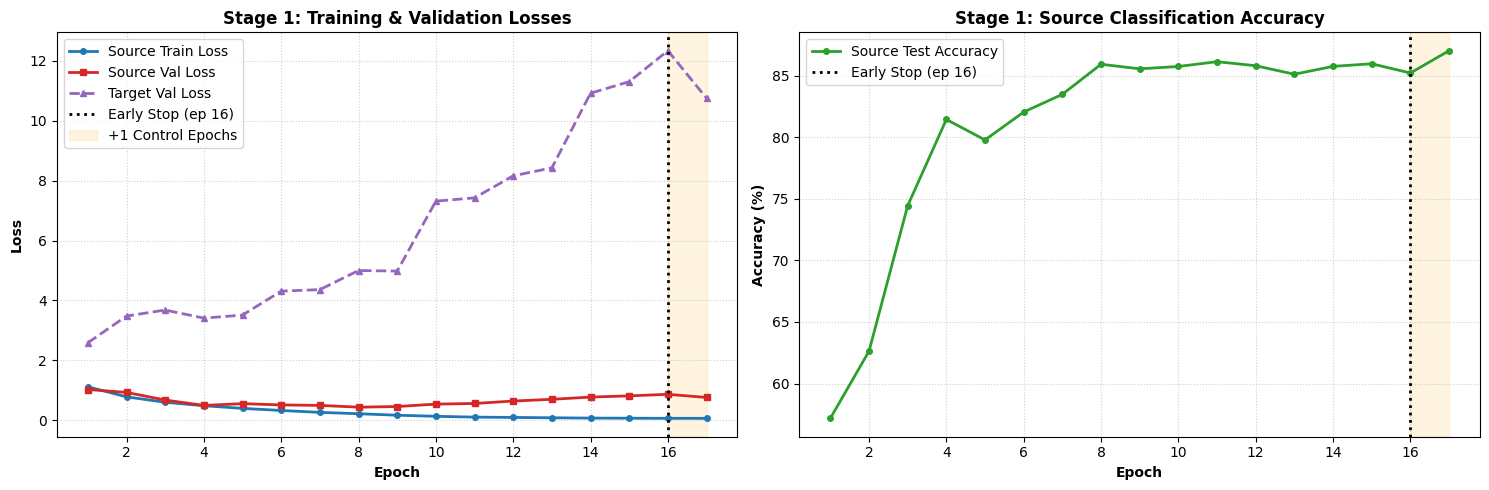

Stage 1 training curves saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_curves_20261119_124357.png


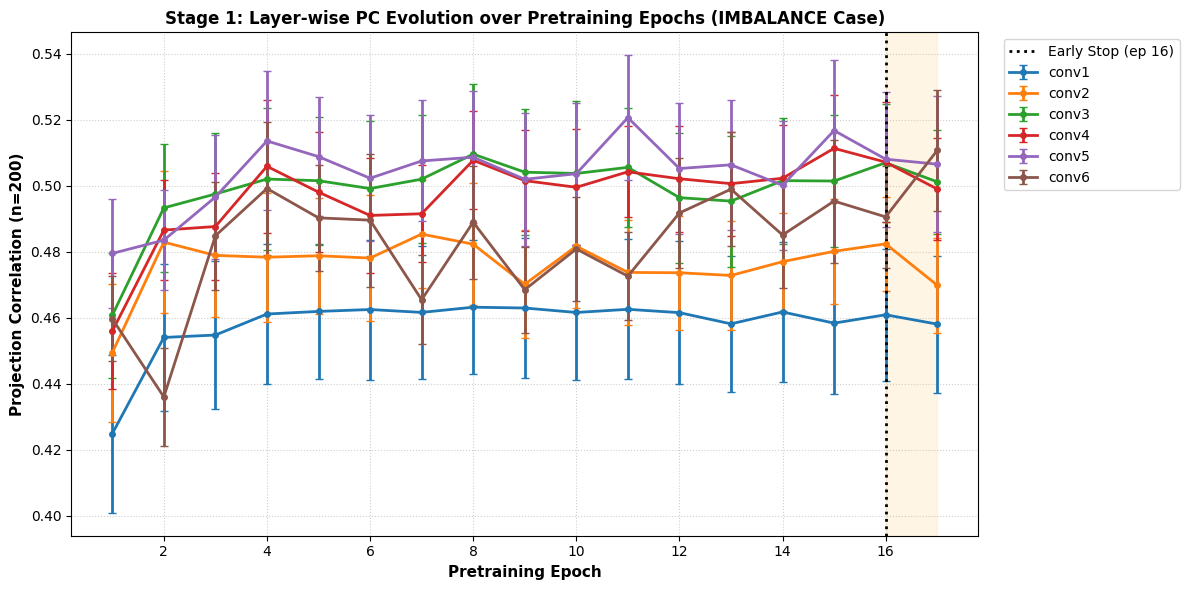

Stage 1 PC evolution plot saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_pc_evolution_20261119_124357.png
[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)
Fixed sample size: n=200 | Early stopping patience: 5 | Max epochs: 50

[Stage 2] Model M_0 (transferred k=0 layers from pre-trained source model)
Fine-tuning on fixed target subset (n=200), monitored metric: Target Validation Loss
[M_0] Epoch 01/50 | Train Loss: 1.6039 | Test Acc: 34.6% | Val Loss: 1.4573 | PC: conv1=0.390±0.025 | conv2=0.432±0.023 | conv3=0.410±0.023 | conv4=0.396±0.024 | conv5=0.396±0.023 | conv6=0.398±0.022 | IPC: conv1=0.403±0.035 | conv2=0.476±0.027 | conv3=0.473±0.028 | conv4=0.469±0.029 | conv5=0.472±0.027 | conv6=0.473±0.027
[M_0] Epoch 02/50 | Train Loss: 1.4015 | Test Acc: 36.0% | Val Loss: 1.3597 | PC: conv1=0.399±0.025 | conv2=0.440±0.022 | conv3=0.422±0.023 | conv4=0.412±0.024 | conv5=0.414±0.022 | conv6=0.414±0.021 | IPC: conv1=0.417±

KeyboardInterrupt: 

In [ ]:
import pc_statistics

def run_experiment_pipeline(
    seed: int = 42,
    experiment_case: str = "imbalance",
    sample_sizes: Optional[List[int]] = None,
    num_replications: int = 10,
    use_real_cifar10: bool = True,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    ft_sample_size: Optional[int] = 1000,
    best_model_criterion: str = 'pc',
    notebook_name: str = "pretrained",
    plot_results: bool = True,
    show_plots: bool = True,
) -> Dict[str, Any]:
    """Execute the full two-stage transfer learning pipeline.

    All calculation parameters are passed explicitly as arguments.
    Can be called repeatedly in a loop across different seeds/configurations
    to gather statistical results.
    """
    # 1. Environment Setup
    device, seed = setup_environment(seed=seed)

    # 2. Experiment Parameters
    params = get_experiment_params(
        experiment_case=experiment_case,
        sample_sizes=sample_sizes,
        num_replications=num_replications,
        use_real_cifar10=use_real_cifar10,
        pretrain_epochs=pretrain_epochs,
        early_stop_patience=early_stop_patience,
        post_early_stop_epochs=post_early_stop_epochs,
        learning_rate_source=learning_rate_source,
        target_epochs=target_epochs,
        target_patience=target_patience,
        learning_rate_target=learning_rate_target,
        feature_extraction=feature_extraction,
        ft_sample_size=ft_sample_size,
        best_model_criterion=best_model_criterion,
        notebook_name=notebook_name,
        seed=seed,
    )

    # 3. Data Loading
    data = load_experiment_data(
        experiment_case=params["EXPERIMENT_CASE"],
        seed=seed,
        use_real_cifar10=params["USE_REAL_CIFAR10"]
    )

    # 4. Selecting and Fixing Target Subsets
    fixed_target_subsets = select_fixed_subsets(
        x_data=data["target_train_x"],
        y_data=data["target_train_y"],
        sample_sizes=params["SAMPLE_SIZES"],
        num_replications=params["NUM_REPLICATIONS"],
        base_seed=seed,
    )

    # 5. Stage 1: Source Pretraining
    stage1_res = run_stage1_pretraining(
        device=device,
        seed=seed,
        loaders=data["loaders"],
        num_source_classes=data["num_source_classes"],
        fixed_target_subsets=fixed_target_subsets,
        primary_sample_size=params["SAMPLE_SIZES"][0],
        num_target_classes=data["num_target_classes"],
        target_test_loader=data["target_test_loader"],
        pretrain_epochs=params["PRETRAIN_EPOCHS"],
        early_stop_patience=params["EARLY_STOP_PATIENCE"],
        post_early_stop_epochs=params["POST_EARLY_STOP_EPOCHS"],
        learning_rate_source=params["LEARNING_RATE_SOURCE"],
        best_model_criterion=params["BEST_MODEL_CRITERION"],
        experiment_case=params["EXPERIMENT_CASE"],
        results_dir=params["RESULTS_DIR"]
    )

    # === Statistics PC/IPC according to pc_stat.txt ===
    ref_epochs = [e for e in [
        stage1_res.get("best_pc_epoch"),
        stage1_res.get("best_ipc_epoch"),
        stage1_res.get("early_stop_epoch"),
        len(stage1_res["stage1_history"]),
    ] if e is not None]
    pc_stat_result = pc_statistics.compute_and_save(
        log_dir=stage1_res["log_dir"],
        csv_path=stage1_res["csv_path"],
        reference_epochs=ref_epochs,
        params=params,
    )
    stage1_res["pc_statistics"] = pc_stat_result

    # 6. Stage 1 Visualizations
    stage1_plots = None
    if plot_results:
        stage1_plots = plot_stage1_visualizations(
            stage1_history=stage1_res["stage1_history"],
            stage1_ts=stage1_res["stage1_ts"],
            primary_sample_size=params["SAMPLE_SIZES"][0],
            experiment_case=params["EXPERIMENT_CASE"],
            early_stop_epoch=stage1_res["early_stop_epoch"],
            post_early_stop_epochs=params["POST_EARLY_STOP_EPOCHS"],
            results_dir=params["RESULTS_DIR"],
            show_plots=show_plots
        )

    # 7. Stage 2: Target Fine-Tuning
    stage2_res = run_stage2_finetuning(
        best_source_state=stage1_res["best_source_state"],
        source_model=stage1_res["source_model"],
        loaders=data["loaders"],
        target_test_loader=data["target_test_loader"],
        fixed_target_subsets=fixed_target_subsets,
        device=device,
        target_train_x=data["target_train_x"],
        target_train_y=data["target_train_y"],
        num_target_classes=data["num_target_classes"],
        primary_sample_size=params["SAMPLE_SIZES"][0],
        ft_sample_size=params["FT_SAMPLE_SIZE"],
        target_epochs=params["TARGET_EPOCHS"],
        target_patience=params["TARGET_PATIENCE"],
        learning_rate_target=params["LEARNING_RATE_TARGET"],
        feature_extraction=params["FEATURE_EXTRACTION"],
        experiment_case=params["EXPERIMENT_CASE"],
        results_dir=params["RESULTS_DIR"],
        seed=seed,
        generator=data["generator"]
    )

    # 8. Stage 2 Visualizations
    stage2_plots = None
    if plot_results:
        stage2_plots = plot_stage2_visualizations(
            stage2_results=stage2_res["stage2_results"],
            stage2_ts=stage2_res["stage2_ts"],
            primary_sample_size=params["SAMPLE_SIZES"][0],
            experiment_case=params["EXPERIMENT_CASE"],
            results_dir=params["RESULTS_DIR"],
            show_plots=show_plots
        )

    # 9. Experiment Summary
    artifacts = summarize_experiment(results_dir=params["RESULTS_DIR"])

    return {
        "params": params,
        "seed": seed,
        "stage1_results": stage1_res,
        "stage2_results": stage2_res,
        "stage1_plots": stage1_plots,
        "stage2_plots": stage2_plots,
        "artifacts": artifacts
    }


# =========================================================================
# 1. Execution of the pipeline with explicit parameters
# =========================================================================
# All calculation parameters are passed explicitly as arguments:
results = run_experiment_pipeline(
    seed=42,
    experiment_case="imbalance",
    sample_sizes=[200],
    num_replications=10,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=1000,
    best_model_criterion='pc',
    notebook_name="pretrained",
    plot_results=True,
    show_plots=True
)

# =========================================================================
# 2. Example: Multi-run loop for statistical analysis across multiple seeds
# =========================================================================
# To gather statistics across multiple runs, iterate over seeds:
#
# seeds_to_run = [42, 43, 44, 45, 46]
# multi_run_stats = []
# for s in seeds_to_run:
#     print(f"\n{'='*75}\n>>> Running Experiment Replication with Seed={s} <<<\n{'='*75}\n")
#     res = run_experiment_pipeline(
#         seed=s,
#         experiment_case="imbalance",
#         sample_sizes=[200],
#         num_replications=10,
#         use_real_cifar10=True,
#         pretrain_epochs=50,
#         early_stop_patience=5,
#         post_early_stop_epochs=1,
#         target_epochs=50,
#         target_patience=5,
#         learning_rate_target=0.001,
#         feature_extraction=True,
#         ft_sample_size=1000,
#         best_model_criterion='pc',
#         notebook_name="pretrained_stats",
#         plot_results=False  # disable plots during batch runs
#     )
#     best_k = res["stage2_results"]["best_k_idx"]
#     best_model_metrics = res["stage2_results"]["stage2_results"][best_k]
#     multi_run_stats.append({
#         "seed": s,
#         "optimal_k": best_k,
#         "best_val_loss": best_model_metrics["best_val_loss"],
#         "best_test_acc": best_model_metrics["best_test_acc"],
#         "early_stop_epoch": best_model_metrics["early_stop_epoch"]
#     })


In [ ]:
# =========================================================================

# Ячейка 22: расчёт статистики PC/IPC из лога Stage 1

# Переиспользует setup_environment (cell 3) и get_experiment_params (cell 5)

# =========================================================================



seed=42

experiment_case="imbalance"

sample_sizes=[200]

num_replications=10

use_real_cifar10=True

pretrain_epochs=50

early_stop_patience=5

post_early_stop_epochs=1

learning_rate_source=0.001

target_epochs=50

target_patience=5

learning_rate_target=0.001

feature_extraction=True

ft_sample_size=1000

best_model_criterion='pc'

notebook_name="pretrained"

plot_results=True

show_plots=True



import os





# =========================================================================

# 1. Вызов setup_environment (подключает Google Drive, если ещё не подключён)

#    Функция уже определена в ячейке 3.

# =========================================================================

device, seed = setup_environment(seed=42)

import pc_statistics
import importlib
importlib.reload(pc_statistics)

# =========================================================================

# 2. Параметры эксперимента через get_experiment_params (ячейка 5)

# =========================================================================

params = get_experiment_params(

        experiment_case=experiment_case,

        sample_sizes=sample_sizes,

        num_replications=num_replications,

        use_real_cifar10=use_real_cifar10,

        pretrain_epochs=pretrain_epochs,

        early_stop_patience=early_stop_patience,

        post_early_stop_epochs=post_early_stop_epochs,

        learning_rate_source=learning_rate_source,

        target_epochs=target_epochs,

        target_patience=target_patience,

        learning_rate_target=learning_rate_target,

        feature_extraction=feature_extraction,

        ft_sample_size=ft_sample_size,

        best_model_criterion=best_model_criterion,

        notebook_name=notebook_name,

        seed=seed,

    )





RESULTS_DIR = params["RESULTS_DIR"]

EXPERIMENT_CASE = params["EXPERIMENT_CASE"]

SAMPLE_SIZES = params["SAMPLE_SIZES"]

NUM_REPLICATIONS = params["NUM_REPLICATIONS"]

PRETRAIN_EPOCHS = params["PRETRAIN_EPOCHS"]

EARLY_STOP_PATIENCE = params["EARLY_STOP_PATIENCE"]

POST_EARLY_STOP_EPOCHS = params["POST_EARLY_STOP_EPOCHS"]

LEARNING_RATE_SOURCE = params["LEARNING_RATE_SOURCE"]

BEST_MODEL_CRITERION = params["BEST_MODEL_CRITERION"]

SEED = params["SEED"]



# =========================================================================

# =========================================================================
# 3. Параметры для хеша (без загрузки данных — только скалярные константы)
# =========================================================================
primary_sample_size = int(params["SAMPLE_SIZES"][0])

# =========================================================================
# 4. Расчёт хеша существующей функцией pc_statistics.short_hash_from_params
#    (те же параметры, что в cell 11 run_stage1_pretraining)
#    Хеш не зависит от загруженных данных — только от гиперпараметров запуска.
# =========================================================================
hash_params = {
    "best_model_criterion": str(BEST_MODEL_CRITERION),
    "early_stop_patience": int(EARLY_STOP_PATIENCE),
    "experiment_case": str(EXPERIMENT_CASE),
    "learning_rate_source": float(LEARNING_RATE_SOURCE),
    "num_replications": int(NUM_REPLICATIONS),
    "post_early_stop_epochs": int(POST_EARLY_STOP_EPOCHS),
    "pretrain_epochs": int(PRETRAIN_EPOCHS),
    "primary_sample_size": primary_sample_size,
    "seed": int(seed),
}

short_hash = pc_statistics.short_hash_from_params(hash_params)
top_level_func_name = "run_stage1_pretraining"


# =========================================================================

# 4. Определение имени лога по тому же алгоритму, что в cell 11:

#    log_dir = RESULTS_DIR / f"{top_level_func_name}_{short_hash}"

# =========================================================================

log_dir = os.path.join(RESULTS_DIR, f"{top_level_func_name}_{short_hash}")

csv_path = os.path.join(log_dir, "pc_ipc_layer_profiles.csv")



print(f"Результаты директория: {RESULTS_DIR}")

print(f"Лог директория: {log_dir}")

print(f"CSV файл: {csv_path}")

print(f"Short hash: {short_hash}")



# =========================================================================

# 5. Если лог существует — считаем статистику, иначе — сообщение

# =========================================================================

if os.path.isdir(log_dir) and os.path.isfile(csv_path):

    print(f"\nНайден лог: {log_dir}")

    print(f"Файл CSV: {csv_path}")

    stat_result = pc_statistics.compute_and_save(

        log_dir=log_dir,

        csv_path=csv_path,

    )

    print("\nРасчёт статистики завершён.")

else:

    print(f"\nЛог не найден: {log_dir}")

    print(f"Файл не существует: {csv_path}")

    print("Сначала запустите Stage 1 претренирования, ")

    print("чтобы создать лог с файлом pc_ipc_layer_profiles.csv.")



[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cpu
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Результаты директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Лог директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
CSV файл: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
Short hash: 0a8cfef9

Найден лог: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
Файл CSV: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
СТАТИСТИКА PC/IPC согласно pc_stat.txt
Обозн

## 11. Layer-wise Covariance Matrices for Source PC and IPC per Epoch
В этой ячейке вычисляются межслойные матрицы ковариации для исходных PC и для IPC по bootstrap-выборкам для каждой эпохи претренирования ($L = 6$, размерность каждой матрицы $6 \times 6 = 36$ элементов).
Для каждой эпохи матрица ковариации записывается в одну строку (векторный вид и табличный вид), рассчитываются дисперсии общего уровня $\mathrm{Var}(\mu_{PC})$, $\mathrm{Var}(\mu_{IPC})$ и стандартные ошибки $SE(\mu_{PC})$, $SE(\mu_{IPC})$. Результаты сохраняются в отчёты `.txt`, `.json` и `.csv`.


In [ ]:
# =========================================================================
# Ячейка 23: расчёт матриц ковариации исходных PC и IPC по эпохам
# Переиспользует setup_environment (cell 3) и get_experiment_params (cell 5)
# =========================================================================

seed = 42
experiment_case = "imbalance"
sample_sizes = [200]
num_replications = 10
use_real_cifar10 = True
pretrain_epochs = 50
early_stop_patience = 5
post_early_stop_epochs = 1
learning_rate_source = 0.001
target_epochs = 50
target_patience = 5
learning_rate_target = 0.001
feature_extraction = True
ft_sample_size = 1000
best_model_criterion = 'pc'
notebook_name = "pretrained"
plot_results = True
show_plots = True

import os

# =========================================================================
# 1. Вызов setup_environment (подключает Google Drive, если ещё не подключён)
#    Функция уже определена в ячейке 3.
# =========================================================================
device, seed = setup_environment(seed=42)

import pc_statistics
import importlib
importlib.reload(pc_statistics)

# =========================================================================
# 2. Параметры эксперимента через get_experiment_params (ячейка 5)
# =========================================================================
params = get_experiment_params(
    experiment_case=experiment_case,
    sample_sizes=sample_sizes,
    num_replications=num_replications,
    use_real_cifar10=use_real_cifar10,
    pretrain_epochs=pretrain_epochs,
    early_stop_patience=early_stop_patience,
    post_early_stop_epochs=post_early_stop_epochs,
    learning_rate_source=learning_rate_source,
    target_epochs=target_epochs,
    target_patience=target_patience,
    learning_rate_target=learning_rate_target,
    feature_extraction=feature_extraction,
    ft_sample_size=ft_sample_size,
    best_model_criterion=best_model_criterion,
    notebook_name=notebook_name,
    seed=seed,
)

RESULTS_DIR = params["RESULTS_DIR"]
EXPERIMENT_CASE = params["EXPERIMENT_CASE"]
SAMPLE_SIZES = params["SAMPLE_SIZES"]
NUM_REPLICATIONS = params["NUM_REPLICATIONS"]
PRETRAIN_EPOCHS = params["PRETRAIN_EPOCHS"]
EARLY_STOP_PATIENCE = params["EARLY_STOP_PATIENCE"]
POST_EARLY_STOP_EPOCHS = params["POST_EARLY_STOP_EPOCHS"]
LEARNING_RATE_SOURCE = params["LEARNING_RATE_SOURCE"]
BEST_MODEL_CRITERION = params["BEST_MODEL_CRITERION"]
SEED = params["SEED"]

# =========================================================================
# 3. Параметры для хеша (без загрузки данных — только скалярные константы)
# =========================================================================
primary_sample_size = int(params["SAMPLE_SIZES"][0])

# =========================================================================
# 4. Расчёт хеша существующей функцией pc_statistics.short_hash_from_params
#    (те же параметры, что в cell 11 run_stage1_pretraining)
#    Хеш не зависит от загруженных данных — только от гиперпараметров запуска.
# =========================================================================
hash_params = {
    "best_model_criterion": str(BEST_MODEL_CRITERION),
    "early_stop_patience": int(EARLY_STOP_PATIENCE),
    "experiment_case": str(EXPERIMENT_CASE),
    "learning_rate_source": float(LEARNING_RATE_SOURCE),
    "num_replications": int(NUM_REPLICATIONS),
    "post_early_stop_epochs": int(POST_EARLY_STOP_EPOCHS),
    "pretrain_epochs": int(PRETRAIN_EPOCHS),
    "primary_sample_size": primary_sample_size,
    "seed": int(seed),
}

short_hash = pc_statistics.short_hash_from_params(hash_params)
top_level_func_name = "run_stage1_pretraining"

log_dir = os.path.join(RESULTS_DIR, f"{top_level_func_name}_{short_hash}")
csv_path = os.path.join(log_dir, "pc_ipc_layer_profiles.csv")

print(f"Результаты директория: {RESULTS_DIR}")
print(f"Лог директория: {log_dir}")
print(f"CSV файл: {csv_path}")
print(f"Short hash: {short_hash}")

# =========================================================================
# 5. Если лог существует — считаем матрицы ковариации PC и IPC по эпохам
# =========================================================================
if os.path.isdir(log_dir) and os.path.isfile(csv_path):
    print(f"\nНайден лог: {log_dir}")
    print(f"Файл CSV: {csv_path}")
    cov_result = pc_statistics.compute_and_save_covariance(
        log_dir=log_dir,
        csv_path=csv_path,
        ddof=0,
    )
    print("\nРасчёт матриц ковариации PC и IPC завершён.")
else:
    print(f"\nЛог не найден: {log_dir}")
    print(f"Файл не существует: {csv_path}")
    print("Сначала запустите Stage 1 претренирования, ")
    print("чтобы создать лог с файлом pc_ipc_layer_profiles.csv.")


[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cpu
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Результаты директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Лог директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
CSV файл: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
Short hash: 0a8cfef9

Найден лог: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
Файл CSV: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
ОТЧЁТ: МЕЖСЛОЙНЫЕ МАТРИЦЫ КОВАРИАЦИИ PC И IP

## 12. Layer-wise Correlation Matrices for Source PC and IPC per Epoch
В этой ячейке вычисляются межслойные матрицы корреляции Пирсона для исходных PC и для IPC по bootstrap-выборкам для каждой эпохи претренирования ($L = 6$, размерность каждой матрицы $6 \times 6 = 36$ элементов, 15 уникальных межслойных пар $i < j$).
Для каждой эпохи матрица корреляции записывается в одну строку (векторный вид из всех 36 элементов и компактный табличный вид для 15 пар), рассчитываются средние межслойные корреляции $\bar{r}$, минимум $\min r$ и максимум $\max r$. Результаты сохраняются в отчёты `.txt`, `.json` и `.csv`.

In [ ]:
# =========================================================================
# Ячейка 26: расчёт матриц корреляции исходных PC и IPC по эпохам
# Переиспользует setup_environment (cell 3) и get_experiment_params (cell 5)
# =========================================================================

seed = 42
experiment_case = "imbalance"
sample_sizes = [200]
num_replications = 10
use_real_cifar10 = True
pretrain_epochs = 50
early_stop_patience = 5
post_early_stop_epochs = 1
learning_rate_source = 0.001
target_epochs = 50
target_patience = 5
learning_rate_target = 0.001
feature_extraction = True
ft_sample_size = 1000
best_model_criterion = 'pc'
notebook_name = "pretrained"
plot_results = True
show_plots = True

import os

# =========================================================================
# 1. Вызов setup_environment (подключает Google Drive, если ещё не подключён)
#    Функция уже определена в ячейке 3.
# =========================================================================
device, seed = setup_environment(seed=42)

import pc_statistics
import importlib
importlib.reload(pc_statistics)

# =========================================================================
# 2. Параметры эксперимента через get_experiment_params (ячейка 5)
# =========================================================================
params = get_experiment_params(
    experiment_case=experiment_case,
    sample_sizes=sample_sizes,
    num_replications=num_replications,
    use_real_cifar10=use_real_cifar10,
    pretrain_epochs=pretrain_epochs,
    early_stop_patience=early_stop_patience,
    post_early_stop_epochs=post_early_stop_epochs,
    learning_rate_source=learning_rate_source,
    target_epochs=target_epochs,
    target_patience=target_patience,
    learning_rate_target=learning_rate_target,
    feature_extraction=feature_extraction,
    ft_sample_size=ft_sample_size,
    best_model_criterion=best_model_criterion,
    notebook_name=notebook_name,
    seed=seed,
)

RESULTS_DIR = params["RESULTS_DIR"]
EXPERIMENT_CASE = params["EXPERIMENT_CASE"]
SAMPLE_SIZES = params["SAMPLE_SIZES"]
NUM_REPLICATIONS = params["NUM_REPLICATIONS"]
PRETRAIN_EPOCHS = params["PRETRAIN_EPOCHS"]
EARLY_STOP_PATIENCE = params["EARLY_STOP_PATIENCE"]
POST_EARLY_STOP_EPOCHS = params["POST_EARLY_STOP_EPOCHS"]
LEARNING_RATE_SOURCE = params["LEARNING_RATE_SOURCE"]
BEST_MODEL_CRITERION = params["BEST_MODEL_CRITERION"]
SEED = params["SEED"]

# =========================================================================
# 3. Параметры для хеша (без загрузки данных — только скалярные константы)
# =========================================================================
primary_sample_size = int(params["SAMPLE_SIZES"][0])

# =========================================================================
# 4. Расчёт хеша существующей функцией pc_statistics.short_hash_from_params
#    (те же параметры, что в cell 11 run_stage1_pretraining)
#    Хеш не зависит от загруженных данных — только от гиперпараметров запуска.
# =========================================================================
hash_params = {
    "best_model_criterion": str(BEST_MODEL_CRITERION),
    "early_stop_patience": int(EARLY_STOP_PATIENCE),
    "experiment_case": str(EXPERIMENT_CASE),
    "learning_rate_source": float(LEARNING_RATE_SOURCE),
    "num_replications": int(NUM_REPLICATIONS),
    "post_early_stop_epochs": int(POST_EARLY_STOP_EPOCHS),
    "pretrain_epochs": int(PRETRAIN_EPOCHS),
    "primary_sample_size": primary_sample_size,
    "seed": int(seed),
}

short_hash = pc_statistics.short_hash_from_params(hash_params)
top_level_func_name = "run_stage1_pretraining"

log_dir = os.path.join(RESULTS_DIR, f"{top_level_func_name}_{short_hash}")
csv_path = os.path.join(log_dir, "pc_ipc_layer_profiles.csv")

print(f"Результаты директория: {RESULTS_DIR}")
print(f"Лог директория: {log_dir}")
print(f"CSV файл: {csv_path}")
print(f"Short hash: {short_hash}")

# =========================================================================
# 5. Если лог существует — считаем матрицы корреляции PC и IPC по эпохам
# =========================================================================
if os.path.isdir(log_dir) and os.path.isfile(csv_path):
    print(f"\nНайден лог: {log_dir}")
    print(f"Файл CSV: {csv_path}")
    corr_result = pc_statistics.compute_and_save_correlation(
        log_dir=log_dir,
        csv_path=csv_path,
    )
    print("\nРасчёт матриц корреляции PC и IPC завершён.")
else:
    print(f"\nЛог не найден: {log_dir}")
    print(f"Файл не существует: {csv_path}")
    print("Сначала запустите Stage 1 претренирования, ")
    print("чтобы создать лог с файлом pc_ipc_layer_profiles.csv.")


[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cpu
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Результаты директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Лог директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
CSV файл: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
Short hash: 0a8cfef9

Найден лог: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
Файл CSV: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
ОТЧЁТ: МЕЖСЛОЙНЫЕ МАТРИЦЫ КОРРЕЛЯЦИИ PC И IP

## 13. Top-1 vs Top-2 Layer Difference and Error Analysis (Naive vs Correlated)
В этой ячейке вычисляется статистическая различимость лучшего слоя (Top-1 с максимальной корреляцией) и второго по величине слоя (Top-2) для каждой эпохи претренирования:
- Указываются имена и порядковые номера слоёв ($l_1, l_2 \in \{1..6\}$);
- Находится разность их средних значений $\Delta = \mathrm{Val}_{\mathrm{top1}} - \mathrm{Val}_{\mathrm{top2}} \ge 0$;
- Рассчитывается 'наивная' ошибка разности без учёта корреляции: $SE_{\mathrm{naive}} = \sqrt{s_1^2 + s_2^2}$;
- Рассчитывается истинная ошибка с полным учётом межслойной ковариации: $SE_{\mathrm{corr}} = \sqrt{s_1^2 + s_2^2 - 2\,\mathrm{Cov}(X_1, X_2)}$;
- Находятся отношения разности к ошибкам (Signal-to-Noise Ratio, SNR / $t$-статистика): $\mathrm{SNR}_{\mathrm{naive}} = \Delta / SE_{\mathrm{naive}}$ и $\mathrm{SNR}_{\mathrm{corr}} = \Delta / SE_{\mathrm{corr}}$;
- Оценивается коэффициент выигрыша $\mathrm{Gain} = SE_{\mathrm{naive}} / SE_{\mathrm{corr}}$ от синфазности флуктуаций слоёв.
Расчёт выполняется отдельно для проекционной корреляции (PC) и для инверсной проекционной корреляции (IPC), результаты сохраняются в `.txt`, `.json` и `.csv`.

In [ ]:
# =========================================================================
# Ячейка 28: анализ разности Top-1 и Top-2 слоёв (наивная ошибка vs корреляция)
# Переиспользует setup_environment (cell 3) и get_experiment_params (cell 5)
# =========================================================================

seed = 42
experiment_case = "imbalance"
sample_sizes = [200]
num_replications = 10
use_real_cifar10 = True
pretrain_epochs = 50
early_stop_patience = 5
post_early_stop_epochs = 1
learning_rate_source = 0.001
target_epochs = 50
target_patience = 5
learning_rate_target = 0.001
feature_extraction = True
ft_sample_size = 1000
best_model_criterion = 'pc'
notebook_name = "pretrained"
plot_results = True
show_plots = True

import os

# =========================================================================
# 1. Вызов setup_environment (подключает Google Drive, если ещё не подключён)
#    Функция уже определена в ячейке 3.
# =========================================================================
device, seed = setup_environment(seed=42)

import pc_statistics
import importlib
importlib.reload(pc_statistics)

# =========================================================================
# 2. Параметры эксперимента через get_experiment_params (ячейка 5)
# =========================================================================
params = get_experiment_params(
    experiment_case=experiment_case,
    sample_sizes=sample_sizes,
    num_replications=num_replications,
    use_real_cifar10=use_real_cifar10,
    pretrain_epochs=pretrain_epochs,
    early_stop_patience=early_stop_patience,
    post_early_stop_epochs=post_early_stop_epochs,
    learning_rate_source=learning_rate_source,
    target_epochs=target_epochs,
    target_patience=target_patience,
    learning_rate_target=learning_rate_target,
    feature_extraction=feature_extraction,
    ft_sample_size=ft_sample_size,
    best_model_criterion=best_model_criterion,
    notebook_name=notebook_name,
    seed=seed,
)

RESULTS_DIR = params["RESULTS_DIR"]
EXPERIMENT_CASE = params["EXPERIMENT_CASE"]
SAMPLE_SIZES = params["SAMPLE_SIZES"]
NUM_REPLICATIONS = params["NUM_REPLICATIONS"]
PRETRAIN_EPOCHS = params["PRETRAIN_EPOCHS"]
EARLY_STOP_PATIENCE = params["EARLY_STOP_PATIENCE"]
POST_EARLY_STOP_EPOCHS = params["POST_EARLY_STOP_EPOCHS"]
LEARNING_RATE_SOURCE = params["LEARNING_RATE_SOURCE"]
BEST_MODEL_CRITERION = params["BEST_MODEL_CRITERION"]
SEED = params["SEED"]

# =========================================================================
# 3. Параметры для хеша (без загрузки данных — только скалярные константы)
# =========================================================================
primary_sample_size = int(params["SAMPLE_SIZES"][0])

# =========================================================================
# 4. Расчёт хеша существующей функцией pc_statistics.short_hash_from_params
#    (те же параметры, что в cell 11 run_stage1_pretraining)
#    Хеш не зависит от загруженных данных — только от гиперпараметров запуска.
# =========================================================================
hash_params = {
    "best_model_criterion": str(BEST_MODEL_CRITERION),
    "early_stop_patience": int(EARLY_STOP_PATIENCE),
    "experiment_case": str(EXPERIMENT_CASE),
    "learning_rate_source": float(LEARNING_RATE_SOURCE),
    "num_replications": int(NUM_REPLICATIONS),
    "post_early_stop_epochs": int(POST_EARLY_STOP_EPOCHS),
    "pretrain_epochs": int(PRETRAIN_EPOCHS),
    "primary_sample_size": primary_sample_size,
    "seed": int(seed),
}

short_hash = pc_statistics.short_hash_from_params(hash_params)
top_level_func_name = "run_stage1_pretraining"

log_dir = os.path.join(RESULTS_DIR, f"{top_level_func_name}_{short_hash}")
csv_path = os.path.join(log_dir, "pc_ipc_layer_profiles.csv")

print(f"Результаты директория: {RESULTS_DIR}")
print(f"Лог директория: {log_dir}")
print(f"CSV файл: {csv_path}")
print(f"Short hash: {short_hash}")

# =========================================================================
# 5. Если лог существует — считаем разность Top-1 и Top-2 слоёв и ошибки
# =========================================================================
if os.path.isdir(log_dir) and os.path.isfile(csv_path):
    print(f"\nНайден лог: {log_dir}")
    print(f"Файл CSV: {csv_path}")
    diff_result = pc_statistics.compute_and_save_top1_top2_difference(
        log_dir=log_dir,
        csv_path=csv_path,
        ddof=0,
    )
    print("\nРасчёт разности Top-1 и Top-2 слоёв завершён.")
else:
    print(f"\nЛог не найден: {log_dir}")
    print(f"Файл не существует: {csv_path}")
    print("Сначала запустите Stage 1 претренирования, ")
    print("чтобы создать лог с файлом pc_ipc_layer_profiles.csv.")


[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cpu
Random seed fixed: 42
Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Mode: imbalance | Sample sizes: [200] | Replications: 10
Post early-stopping control epochs: 1
Результаты директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained
Лог директория: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
CSV файл: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
Short hash: 0a8cfef9

Найден лог: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9
Файл CSV: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/pc_ipc_layer_profiles.csv
ОТЧЁТ: СТАТИСТИЧЕСКИЙ АНАЛИЗ РАЗНОСТИ TOP-1 

# Stage 2 standalone launch: reads one epoch checkpoint directly from Stage 1 logs.
# Run setup/import/data-loading cells first; Stage 1 training does not need to run.


In [ ]:
# Stage 2 standalone launch: reads one epoch checkpoint directly from Stage 1 logs.
# Run setup/import/data-loading cells first; Stage 1 training does not need to run.
STAGE1_LOG_DIR = os.path.join(os.getcwd(), "pretrained", "run_stage1_pretraining_0a8cfef9")
n = 8
CALCULATE_PC_IPC = False
STAGE2_SAMPLE_SIZE = 200
STAGE2_FT_SAMPLE_SIZE = 1000
STAGE2_EPOCHS = 50
STAGE2_PATIENCE = 5
STAGE2_LR = 0.001
STAGE2_FEATURE_EXTRACTION = True
STAGE2_EXPERIMENT_CASE = "imbalance"
STAGE2_SEED = 42
STAGE2_OUTPUT_DIR = os.path.join(os.getcwd(), "pretrained")

def run_stage2_from_stage1_logs(stage1_log_dir, n, calculate_pc_ipc=False,
                                sample_size=200, ft_sample_size=1000,
                                target_epochs=50, target_patience=5,
                                learning_rate_target=0.001, feature_extraction=True,
                                experiment_case="imbalance", seed=42, results_dir=None):
    with open(os.path.join(stage1_log_dir, "launch_parameters.json"), encoding="utf-8") as f:
        p = json.load(f)
    with open(os.path.join(stage1_log_dir, "stage1_model_history.json"), encoding="utf-8") as f:
        stage1_log = json.load(f)
    if not 1 <= int(n) <= int(stage1_log["epochs_trained"]):
        raise ValueError(f"n={n} ??? ????????? 1..{stage1_log['epochs_trained']}")
    try:
        epoch_states = torch.load(os.path.join(stage1_log_dir, "stage1_epoch_models.pt"), map_location="cpu", weights_only=False)
    except TypeError:
        epoch_states = torch.load(os.path.join(stage1_log_dir, "stage1_epoch_models.pt"), map_location="cpu")
    device, seed = setup_environment(seed)
    data = load_experiment_data(experiment_case=experiment_case, seed=seed, use_real_cifar10=True)
    subsets = select_fixed_subsets(data["target_train_x"], data["target_train_y"], [sample_size],
                                   int(p.get("num_replications", 10)), base_seed=seed)
    source_model = CIFAR6CNN(num_classes=data["num_source_classes"]).to(device)
    out_dir = results_dir or os.path.join(os.getcwd(), "pretrained")
    result = run_stage2_finetuning(
        best_source_state=epoch_states[int(n)-1], source_model=source_model,
        loaders=data["loaders"], target_test_loader=data["target_test_loader"],
        fixed_target_subsets=subsets, device=device, target_train_x=data["target_train_x"],
        target_train_y=data["target_train_y"], num_target_classes=data["num_target_classes"],
        primary_sample_size=sample_size, ft_sample_size=ft_sample_size,
        target_epochs=target_epochs, target_patience=target_patience,
        learning_rate_target=learning_rate_target, feature_extraction=feature_extraction,
        experiment_case=experiment_case, results_dir=out_dir, seed=seed,
        generator=data["generator"], calculate_pc_ipc=calculate_pc_ipc, source_epoch=int(n))
    # Map Stage 1 layer-wise PC/IPC maxima at epoch n to the corresponding
    # unfreezing boundary: layer index 0 means M_0 (unfreeze from first layer).
    stage1_epoch = stage1_log["history"][int(n)-1]
    profile_key = str(sample_size)
    pc_by_layer = stage1_epoch.get("pc_profiles", {}).get(profile_key, {})
    ipc_by_layer = stage1_epoch.get("ipc_profiles", {}).get(profile_key, {})
    layer_names = list(CIFAR6CNN.LAYER_NAMES)
    if not pc_by_layer or not ipc_by_layer:
        raise ValueError(f"? ???? Stage 1 ??? ????? {n} ??? PC/IPC ???????? ??????? {sample_size}")
    pc_layer = max(pc_by_layer, key=lambda name: pc_by_layer[name]["mean"])
    ipc_layer = max(ipc_by_layer, key=lambda name: ipc_by_layer[name]["mean"])
    pc_k, ipc_k = layer_names.index(pc_layer), layer_names.index(ipc_layer)
    exhaustive_k = max(result["stage2_results"], key=lambda k: result["stage2_results"][k]["best_test_acc"])
    exhaustive_acc = result["stage2_results"][exhaustive_k]["best_test_acc"]
    def di_walk(start_k):
        selected_k = start_k
        for candidate_k in range(start_k + 1, 7):
            if result["stage2_results"][candidate_k]["best_test_acc"] > result["stage2_results"][selected_k]["best_test_acc"]:
                selected_k = candidate_k
            else:
                break
        return selected_k
    di_pc_k, di_ipc_k = di_walk(pc_k), di_walk(ipc_k)
    pc_acc = result["stage2_results"][di_pc_k]["best_test_acc"]
    ipc_acc = result["stage2_results"][di_ipc_k]["best_test_acc"]
    pc_ratio = pc_acc / exhaustive_acc if exhaustive_acc else None
    ipc_ratio = ipc_acc / exhaustive_acc if exhaustive_acc else None
    lines = [f"Stage 1 epoch used: {n}", f"Stage 1 log: {stage1_log_dir}",
             f"PC/IPC calculated and logged in Stage 2: {calculate_pc_ipc}",
             f"Stage 1 max PC layer: {pc_layer}; Di-PC starts at M_{pc_k}, selects M_{di_pc_k}",
             f"Stage 1 max IPC layer: {ipc_layer}; Di-IPC starts at M_{ipc_k}, selects M_{di_ipc_k}",
             f"Best exhaustive Stage 2 model: M_{exhaustive_k} ({exhaustive_acc:.2f}%)",
             "k | Start PC | Start IPC | Di-PC selected | Di-IPC selected | accuracy (%) at minimum val_loss | full-model FT gain (pp) | Di-PC / exhaustive | Di-IPC / exhaustive"]
    summaries = {}
    for k, r in result["stage2_results"].items():
        best_val_loss = r["best_val_loss"]
        best_accuracy = r["best_test_acc"]
        gain = r.get("full_ft_accuracy_gain_pp")
        gain_text = f"{gain:+.2f}" if gain is not None and r.get("full_ft_improved_val_loss") else "not improved"
        pc_ratio_text = f"{pc_ratio:.4f} ({pc_ratio*100:.2f}%)" if k == di_pc_k and pc_ratio is not None else ""
        ipc_ratio_text = f"{ipc_ratio:.4f} ({ipc_ratio*100:.2f}%)" if k == di_ipc_k and ipc_ratio is not None else ""
        lines.append(f"M_{k} | {'*' if k == pc_k else ''} | {'*' if k == ipc_k else ''} | {'*' if k == di_pc_k else ''} | {'*' if k == di_ipc_k else ''} | {best_accuracy:.2f} | {gain_text} | {pc_ratio_text} | {ipc_ratio_text}")
        summaries[str(k)] = {"min_val_loss": best_val_loss, "accuracy_percent": best_accuracy,
                             "source_epoch": int(n), "full_model_ft_accuracy_gain_pp": gain,
                             "full_ft_improved_val_loss": r.get("full_ft_improved_val_loss", False),
                             "selected_by_max_pc": k == pc_k, "selected_by_max_ipc": k == ipc_k,
                             "di_pc_to_exhaustive_accuracy_ratio": pc_ratio if k == pc_k else None,
                             "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio if k == ipc_k else None,
                             "best_exhaustive_model": k == exhaustive_k}
    report_path = make_result_path("stage2_epoch_report", "txt", results_dir=out_dir)
    with open(report_path, "w", encoding="utf-8") as f: f.write("\n".join(lines)+"\n")
    with open(report_path[:-4]+".json", "w", encoding="utf-8") as f:
        json.dump({"source_epoch": int(n), "stage1_log_dir": stage1_log_dir,
                   "calculate_pc_ipc": bool(calculate_pc_ipc), "models": summaries,
                   "max_pc_layer": pc_layer, "max_pc_model": f"M_{pc_k}",
                   "max_ipc_layer": ipc_layer, "max_ipc_model": f"M_{ipc_k}",
                   "best_exhaustive_model": f"M_{exhaustive_k}",
                   "di_pc_model": f"M_{di_pc_k}", "di_ipc_model": f"M_{di_ipc_k}",
                   "di_pc_to_exhaustive_accuracy_ratio": pc_ratio,
                   "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio,
                   "stage2_history_path": result["stage2_history_path"]}, f, indent=2)
    print("\n".join(lines)); print(f"Report saved: {report_path}")
    result["report_path"] = report_path
    return result


[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
Random seed fixed: 42
Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 20000 | test: 10000
Target train size: 20000 | test: 10000
Source classes: 5 | Target classes: 5
[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)
Fixed sample size: n=200 | Early stopping patience: 5 | Max epochs: 50

[Stage 2] Model M_0 (transferred k=0 layers from pre-trained source model)
Fine-tuning on fixed target subset (n=200), monitored metric: Target Validation Loss
[M_0] Epoch 01/50 | Train Loss: 1.5913 | Test Acc: 38.1% | Val Loss: 1.4399 | PC: disabled
[M_0] Epoch 02/50 | Train Loss: 1.3949 | Test Acc: 36.8% | Val Loss: 1.3481 | PC: disabled
[M_0] Epoch 03/50 | Train Loss: 1.3334 | Test Acc: 37.7% | Val Loss:

# Build a neatly aligned comparison table from the latest saved Stage 1 and Stage 2 logs.
# Run this cell by itself; it only reads logs and does not start or repeat training.


In [ ]:
# Build a neatly aligned comparison table from the latest saved Stage 1 and Stage 2 logs.
# Run this cell by itself; it only reads logs and does not start or repeat training.
from pathlib import Path
import json
import os

STAGE2_REPORTS_DIR = Path(os.path.join(os.getcwd(), "pretrained"))


def report_from_latest_stage2_logs(reports_dir=STAGE2_REPORTS_DIR):
    reports_dir = Path(reports_dir)
    candidates = sorted(
        reports_dir.glob("stage2_epoch_report_*.json"),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )
    if not candidates:
        raise FileNotFoundError(f"No stage2_epoch_report_*.json found in {reports_dir}")

    report_path = candidates[0]
    report = json.loads(report_path.read_text(encoding="utf-8"))
    stage1_dir = Path(report["stage1_log_dir"])
    stage1_log = json.loads(
        (stage1_dir / "stage1_model_history.json").read_text(encoding="utf-8")
    )
    source_epoch = int(report["source_epoch"])
    stage1_epoch = stage1_log["history"][source_epoch - 1]

    stage2_log = {}
    stage2_history_path = report.get("stage2_history_path")
    if stage2_history_path and Path(stage2_history_path).exists():
        stage2_log = json.loads(Path(stage2_history_path).read_text(encoding="utf-8"))
    sample_size = int(report.get("target_sample_size", stage2_log.get("target_sample_size", 200)))
    profile_key = str(sample_size)
    pc_profiles = stage1_epoch.get("pc_profiles", {}).get(profile_key, {})
    ipc_profiles = stage1_epoch.get("ipc_profiles", {}).get(profile_key, {})
    if not pc_profiles or not ipc_profiles:
        raise ValueError(
            f"PC/IPC profiles are missing for Stage 1 epoch {source_epoch}, sample size {sample_size}"
        )

    try:
        from models import CIFAR6CNN
        layer_names = list(CIFAR6CNN.LAYER_NAMES)
    except Exception:
        layer_names = list(pc_profiles)

    max_pc_layer = max(pc_profiles, key=lambda layer: pc_profiles[layer]["mean"])
    max_ipc_layer = max(ipc_profiles, key=lambda layer: ipc_profiles[layer]["mean"])
    pc_k = layer_names.index(max_pc_layer)
    ipc_k = layer_names.index(max_ipc_layer)

    report_models = report.get("models", {})
    logged_models = stage2_log.get("models", {})
    models = {}
    for k in range(7):
        model_name = f"M_{k}"
        item = report_models.get(str(k), report_models.get(model_name, {}))
        details = logged_models.get(model_name, {})
        accuracy = item.get(
            "accuracy_percent", item.get("best_test_acc", details.get("best_test_acc"))
        )
        if accuracy is None:
            raise ValueError(f"Accuracy for {model_name} is missing from {report_path}")
        models[k] = {
            "accuracy": float(accuracy),
            "gain": item.get(
                "full_model_ft_accuracy_gain_pp",
                item.get("full_ft_accuracy_gain_pp", details.get("full_ft_accuracy_gain_pp")),
            ),
            "full_ft_improved": item.get(
                "full_ft_improved_val_loss", details.get("full_ft_improved_val_loss", False)
            ),
        }

    exhaustive_k = max(models, key=lambda k: models[k]["accuracy"])
    exhaustive_accuracy = models[exhaustive_k]["accuracy"]

    # Start immediately before the maximum-correlation layer. Move toward the
    # output while accuracy strictly improves; stop at the first tie or decrease.
    def di_walk(start_k):
        selected_k = start_k
        for candidate_k in range(start_k + 1, 7):
            if models[candidate_k]["accuracy"] > models[selected_k]["accuracy"]:
                selected_k = candidate_k
            else:
                break
        return selected_k

    di_pc_k = di_walk(pc_k)
    di_ipc_k = di_walk(ipc_k)
    pc_ratio = models[di_pc_k]["accuracy"] / exhaustive_accuracy if exhaustive_accuracy else None
    ipc_ratio = models[di_ipc_k]["accuracy"] / exhaustive_accuracy if exhaustive_accuracy else None

    headers = [
        "k",
        "Accuracy at min val_loss (%)",
        "Full-model FT gain (pp)",
        "Start PC",
        "Start IPC",
        "Di-PC selected",
        "Di-IPC selected",
        "Di-PC / exhaustive",
        "Di-IPC / exhaustive",
    ]
    rows = []
    for k, item in models.items():
        gain = item["gain"] if item["full_ft_improved"] else None
        gain_text = f"{gain:+.2f}" if gain is not None else "-"
        pc_ratio_text = (
            f"{pc_ratio:.4f} ({pc_ratio * 100:.2f}%)" if k == di_pc_k and pc_ratio is not None else ""
        )
        ipc_ratio_text = (
            f"{ipc_ratio:.4f} ({ipc_ratio * 100:.2f}%)" if k == di_ipc_k and ipc_ratio is not None else ""
        )
        rows.append([
            str(k),
            f"{item['accuracy']:.2f}",
            gain_text,
            "*" if k == pc_k else "",
            "*" if k == ipc_k else "",
            "*" if k == di_pc_k else "",
            "*" if k == di_ipc_k else "",
            pc_ratio_text,
            ipc_ratio_text,
        ])

    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    def format_row(row):
        return " | ".join(value.ljust(widths[i]) for i, value in enumerate(row))
    separator = "-+-".join("-" * width for width in widths)
    table = "\n".join([format_row(headers), separator] + [format_row(row) for row in rows])

    output_lines = [
        f"Stage 2 report: {report_path}",
        f"Stage 1 epoch: {source_epoch}",
        f"Maximum PC layer: {max_pc_layer}; Di-PC starts at M_{pc_k} and selects M_{di_pc_k}",
        f"Maximum IPC layer: {max_ipc_layer}; Di-IPC starts at M_{ipc_k} and selects M_{di_ipc_k}",
        f"Best exhaustive model: M_{exhaustive_k} (accuracy: {exhaustive_accuracy:.2f}%)",
        table,
        "* Start PC/IPC marks the boundary immediately before the maximum-correlation layer.",
        "* Di-PC/Di-IPC marks the last boundary selected while accuracy improves toward the output.",
        "- Full-model fine-tuning did not improve validation loss.",
    ]
    output = "\n".join(output_lines)
    print(output)

    txt_path = reports_dir / f"stage2_log_comparison_epoch_{source_epoch}.txt"
    txt_path.write_text(output + "\n", encoding="utf-8")
    json_path = txt_path.with_suffix(".json")
    json_path.write_text(json.dumps({
        "stage2_report": str(report_path),
        "stage1_log_dir": str(stage1_dir),
        "source_epoch": source_epoch,
        "max_pc_layer": max_pc_layer,
        "max_pc_model": f"M_{pc_k}",
        "max_ipc_layer": max_ipc_layer,
        "max_ipc_model": f"M_{ipc_k}",
        "di_pc_model": f"M_{di_pc_k}",
        "di_ipc_model": f"M_{di_ipc_k}",
        "best_exhaustive_model": f"M_{exhaustive_k}",
        "di_pc_to_exhaustive_accuracy_ratio": pc_ratio,
        "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio,
        "models": {f"M_{k}": models[k] for k in models},
    }, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"\nSaved report files: {txt_path} and {json_path}")
    return {"table": table, "text_path": str(txt_path), "json_path": str(json_path)}

stage2_log_comparison = report_from_latest_stage2_logs()


Stage 2 report: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_epoch_report_20261119_125920.json
Stage 1 epoch: 8
Maximum PC layer: conv3; Di-PC starts at M_2 and selects M_5
Maximum IPC layer: conv3; Di-IPC starts at M_2 and selects M_5
Best exhaustive model: M_5 (accuracy: 69.48%)
k | Accuracy at min val_loss (%) | Full-model FT gain (pp) | Start PC | Start IPC | Di-PC selected | Di-IPC selected | Di-PC / exhaustive | Di-IPC / exhaustive
--+------------------------------+-------------------------+----------+-----------+----------------+-----------------+--------------------+--------------------
0 | 48.84                        | -                       |          |           |                |                 |                    |                    
1 | 54.08                        | -                       |          |           |                |                 |                    |                    
2 | 62.12                        | +42.93        

In [ ]:
# Determine the Stage 1 analysis boundary from a saved Stage 1 history log.
# The learning boundary is the first epoch reaching 80% of the accuracy
# recorded at the epoch with minimum source validation loss.

# Determine the Stage 1 analysis boundary from a saved Stage 1 history log.
# The learning boundary is the first epoch reaching 80% of the accuracy
# recorded at the epoch with minimum source validation loss.

In [ ]:
# Determine the Stage 1 analysis boundary from a saved Stage 1 history log.
# The learning boundary is the first epoch reaching 80% of the accuracy
# recorded at the epoch with minimum source validation loss.
from pathlib import Path
import json
import math


def find_stage1_analysis_boundary(stage1_log_dir=None, accuracy_fraction=0.80):
    if stage1_log_dir is None:
        log_candidates = list((Path.cwd() / "pretrained").glob(
            "run_stage1_pretraining_*/stage1_model_history.json"
        ))
        if not log_candidates:
            raise FileNotFoundError(
                "No Stage 1 history log found under ./pretrained. "
                "Pass stage1_log_dir explicitly."
            )
        history_path = max(log_candidates, key=lambda path: path.stat().st_mtime)
    else:
        stage1_log_dir = Path(stage1_log_dir)
        history_path = stage1_log_dir / "stage1_model_history.json"

    stage1_log = json.loads(history_path.read_text(encoding="utf-8"))
    history = stage1_log.get("history", [])
    if not history:
        raise ValueError(f"Stage 1 history is empty: {history_path}")

    # Use source_test_acc as the Stage 1 accuracy paired with source_val_loss.
    min_loss_row = min(history, key=lambda row: row["source_val_loss"])
    reference_accuracy = float(min_loss_row["source_test_acc"])
    accuracy_threshold = accuracy_fraction * reference_accuracy
    learning_rows = [
        row for row in history
        if float(row["source_test_acc"]) >= accuracy_threshold
    ]
    if not learning_rows:
        raise ValueError(
            f"No epoch reached {accuracy_fraction:.0%} of the reference accuracy "
            f"({accuracy_threshold:.4f}%). Check the Stage 1 accuracy values."
        )
    learning_boundary_epoch = int(min(learning_rows, key=lambda row: row["epoch"])["epoch"])

    def max_absolute_epoch(metric_name):
        valid_rows = [
            row for row in history
            if row.get(metric_name) is not None and math.isfinite(float(row[metric_name]))
        ]
        if not valid_rows:
            raise ValueError(f"Metric '{metric_name}' is missing from {history_path}")
        # max() returns the first matching row on ties, preserving the earliest epoch.
        best_row = max(valid_rows, key=lambda row: abs(float(row[metric_name])))
        return int(best_row["epoch"]), float(best_row[metric_name])

    pc_epoch, pc_value = max_absolute_epoch("current_pc")
    ipc_epoch, ipc_value = max_absolute_epoch("current_ipc")
    candidates = {
        "learning_boundary": learning_boundary_epoch,
        "max_absolute_pc": pc_epoch,
        "max_absolute_ipc": ipc_epoch,
    }
    analysis_boundary = min(candidates.values())

    print(f"Stage 1 log: {history_path}")
    print(
        f"Minimum source_val_loss: {min_loss_row['source_val_loss']:.6f} "
        f"at epoch {min_loss_row['epoch']}; accuracy: {reference_accuracy:.4f}%"
    )
    print(
        f"Learning boundary: epoch {learning_boundary_epoch} "
        f"(first accuracy >= {accuracy_fraction:.0%} of reference = {accuracy_threshold:.4f}%)"
    )
    print(f"Maximum |PC|: epoch {pc_epoch} (PC={pc_value:.8f})")
    print(f"Maximum |IPC|: epoch {ipc_epoch} (IPC={ipc_value:.8f})")
    print(f"Analysis boundary: epoch {analysis_boundary}")

    return {
        "stage1_log_path": str(history_path),
        "minimum_val_loss_epoch": int(min_loss_row["epoch"]),
        "reference_accuracy": reference_accuracy,
        "accuracy_threshold": accuracy_threshold,
        "learning_boundary_epoch": learning_boundary_epoch,
        "max_absolute_pc_epoch": pc_epoch,
        "max_absolute_pc_value": pc_value,
        "max_absolute_ipc_epoch": ipc_epoch,
        "max_absolute_ipc_value": ipc_value,
        "candidate_epochs": candidates,
        "analysis_boundary_epoch": analysis_boundary,
    }

stage1_analysis_boundary = find_stage1_analysis_boundary()


Stage 1 log: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/run_stage1_pretraining_0a8cfef9/stage1_model_history.json
Minimum source_val_loss: 0.434708 at epoch 8; accuracy: 85.9200%
Learning boundary: epoch 3 (first accuracy >= 80% of reference = 68.7360%)
Maximum |PC|: epoch 11 (PC=0.52058791)
Maximum |IPC|: epoch 4 (IPC=0.54020559)
Analysis boundary: epoch 3


# Run Stage 2 for every Stage 1 epoch from the analysis boundary through the final logged epoch.
# The JSONL output contains exactly one compact record (one line) per Stage 1 epoch.


In [ ]:
# Run Stage 2 for every Stage 1 epoch from the analysis boundary through the final logged epoch.
# The JSONL output contains exactly one compact record (one line) per Stage 1 epoch.
from pathlib import Path
from datetime import datetime
import json

# Stage 2 settings for this sweep; adjust these before running if needed.
SWEEP_CALCULATE_PC_IPC = False
SWEEP_SAMPLE_SIZE = 200
SWEEP_FT_SAMPLE_SIZE = 1000
SWEEP_TARGET_EPOCHS = 50
SWEEP_TARGET_PATIENCE = 5
SWEEP_LEARNING_RATE = 0.001
SWEEP_FEATURE_EXTRACTION = True
SWEEP_EXPERIMENT_CASE = "imbalance"
SWEEP_SEED = 42


def run_stage2_for_analysis_epochs():
    if "stage1_analysis_boundary" not in globals():
        raise RuntimeError("Run the Stage 1 analysis-boundary cell first.")
    if "run_stage2_from_stage1_logs" not in globals():
        raise RuntimeError("Load the notebook cell defining run_stage2_from_stage1_logs first.")

    stage1_history_path = Path(stage1_analysis_boundary["stage1_log_path"])
    stage1_log_dir = stage1_history_path.parent
    stage1_log = json.loads(stage1_history_path.read_text(encoding="utf-8"))
    first_epoch = int(stage1_analysis_boundary["analysis_boundary_epoch"])
    last_epoch = int(stage1_log["epochs_trained"])
    if first_epoch > last_epoch:
        raise ValueError(f"Analysis boundary {first_epoch} exceeds final Stage 1 epoch {last_epoch}.")

    output_dir = Path.cwd() / "pretrained"
    output_dir.mkdir(parents=True, exist_ok=True)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    jsonl_path = output_dir / f"stage2_epoch_sweep_{timestamp}.jsonl"
    print(f"Stage 1 epochs: {first_epoch}..{last_epoch}")
    print(f"One-line-per-epoch log: {jsonl_path}")

    with jsonl_path.open("w", encoding="utf-8") as log_file:
        for source_epoch in range(first_epoch, last_epoch + 1):
            print(f"\nRunning Stage 2 from Stage 1 epoch {source_epoch}/{last_epoch}")
            record = {
                "stage1_epoch": source_epoch,
                "status": "ok",
                "stage1_log_dir": str(stage1_log_dir),
            }
            try:
                run = run_stage2_from_stage1_logs(
                    stage1_log_dir=str(stage1_log_dir),
                    n=source_epoch,
                    calculate_pc_ipc=SWEEP_CALCULATE_PC_IPC,
                    sample_size=SWEEP_SAMPLE_SIZE,
                    ft_sample_size=SWEEP_FT_SAMPLE_SIZE,
                    target_epochs=SWEEP_TARGET_EPOCHS,
                    target_patience=SWEEP_TARGET_PATIENCE,
                    learning_rate_target=SWEEP_LEARNING_RATE,
                    feature_extraction=SWEEP_FEATURE_EXTRACTION,
                    experiment_case=SWEEP_EXPERIMENT_CASE,
                    seed=SWEEP_SEED,
                    results_dir=str(output_dir),
                )
                epoch_report_path = Path(run["report_path"]).with_suffix(".json")
                epoch_report = json.loads(epoch_report_path.read_text(encoding="utf-8"))
                record.update({
                    "stage2_report": run["report_path"],
                    "stage2_history": run["stage2_history_path"],
                    "models": epoch_report["models"],
                    "di_pc_model": epoch_report.get("di_pc_model"),
                    "di_ipc_model": epoch_report.get("di_ipc_model"),
                    "best_exhaustive_model": epoch_report.get("best_exhaustive_model"),
                    "di_pc_to_exhaustive_accuracy_ratio": epoch_report.get("di_pc_to_exhaustive_accuracy_ratio"),
                    "di_ipc_to_exhaustive_accuracy_ratio": epoch_report.get("di_ipc_to_exhaustive_accuracy_ratio"),
                })
            except Exception as exc:
                record.update({"status": "error", "error": f"{type(exc).__name__}: {exc}"})
                print(f"Stage 2 failed for source epoch {source_epoch}: {record['error']}")
            log_file.write(json.dumps(record, ensure_ascii=False, separators=(",", ":")) + "\n")
            log_file.flush()

    print(f"\nCompleted epoch sweep. Results: {jsonl_path}")
    return str(jsonl_path)

stage2_epoch_sweep_log = run_stage2_for_analysis_epochs()


Stage 1 epochs: 3..17
One-line-per-epoch log: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_epoch_sweep_20261119_141512.jsonl

Running Stage 2 from Stage 1 epoch 3/17
[Colab] Google Colab environment detected.
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di
Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB
Random seed fixed: 42
Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 20000 | test: 10000
Target train size: 20000 | test: 10000
Source classes: 5 | Target classes: 5
[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)
Fixed sample size: n=200 | Early stopping patience: 5 | Max epochs: 50

[Stage 2] Model M_0 (transferred k=0 layers from pre-trained source model)
Fine-tuning on fixed target subset (n=200), monitored metric: Target Validation Loss
[M_0] Epoch 01/50 | Train Loss: 1.5913 | Test Acc: 38.1

# Combine Stage 1 history and per-epoch Stage 2 sweep logs into one aligned row per epoch.
# This cell only reads existing logs and writes a CSV summary; it does not train models.

In [ ]:
# Combine Stage 1 history and per-epoch Stage 2 sweep logs into one aligned row per epoch.
# This cell only reads existing logs and writes a CSV summary; it does not train models.
from pathlib import Path
import csv
import json
import math

LOGS_ROOT = Path.cwd() / "pretrained"


def collect_stage1_stage2_epoch_summary(logs_root=LOGS_ROOT, sweep_jsonl=None):
    logs_root = Path(logs_root)
    if sweep_jsonl is None:
        sweep_candidates = sorted(
            logs_root.glob("stage2_epoch_sweep_*.jsonl"),
            key=lambda path: path.stat().st_mtime,
            reverse=True,
        )
        if not sweep_candidates:
            raise FileNotFoundError(
                f"No stage2_epoch_sweep_*.jsonl found in {logs_root}. Run the Stage 2 epoch sweep first."
            )
        sweep_jsonl = sweep_candidates[0]
    else:
        sweep_jsonl = Path(sweep_jsonl)

    records = [
        json.loads(line)
        for line in sweep_jsonl.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    valid_records = [row for row in records if row.get("status") == "ok"]
    if not valid_records:
        raise ValueError(f"No successful Stage 2 records in {sweep_jsonl}")

    stage1_dir = Path(valid_records[0]["stage1_log_dir"])
    stage1_path = stage1_dir / "stage1_model_history.json"
    stage1_log = json.loads(stage1_path.read_text(encoding="utf-8"))
    history_by_epoch = {int(row["epoch"]): row for row in stage1_log["history"]}

    params_path = stage1_dir / "launch_parameters.json"
    launch_params = json.loads(params_path.read_text(encoding="utf-8")) if params_path.exists() else {}
    sample_size = int(launch_params.get("primary_sample_size", 200))
    profile_key = str(sample_size)
    try:
        from models import CIFAR6CNN
        layer_names = list(CIFAR6CNN.LAYER_NAMES)
    except Exception:
        first_history = next(iter(history_by_epoch.values()))
        layer_names = list(first_history.get("pc_profiles", {}).get(profile_key, {}))

    stage2_by_epoch = {int(row["stage1_epoch"]): row for row in records}
    headers = [
        "Stage1 epoch", "Stage1 val_loss", "Stage1 accuracy (%)",
        "Max |PC|", "Max |IPC|", "Max PC layer", "Max IPC layer",
        "Best FT accuracy (%)", "Best FT gain (pp)",
        "Di-PC model accuracy (%)", "Di-IPC model accuracy (%)",
        "Di-PC / exhaustive", "Di-IPC / exhaustive",
        "Di-PC start k", "Di-PC selected k", "Di-PC delta k",
        "Di-IPC start k", "Di-IPC selected k", "Di-IPC delta k",
    ]
    output_rows = []

    def model_entry(model_map, k):
        return model_map.get(str(k), model_map.get(f"M_{k}", {}))

    for epoch in sorted(stage2_by_epoch):
        stage1_row = history_by_epoch.get(epoch)
        sweep_row = stage2_by_epoch[epoch]
        if stage1_row is None:
            continue
        base = {
            "Stage1 epoch": epoch,
            "Stage1 val_loss": float(stage1_row["source_val_loss"]),
            "Stage1 accuracy (%)": float(stage1_row["source_test_acc"]),
        }
        if sweep_row.get("status") != "ok":
            output_rows.append({**base, "Stage 2 status": sweep_row.get("error", "failed")})
            continue

        profiles_pc = stage1_row.get("pc_profiles", {}).get(profile_key, {})
        profiles_ipc = stage1_row.get("ipc_profiles", {}).get(profile_key, {})
        if not profiles_pc or not profiles_ipc:
            raise ValueError(f"PC/IPC profiles missing in Stage 1 epoch {epoch}, sample size {sample_size}")
        max_pc_layer = max(profiles_pc, key=lambda name: abs(float(profiles_pc[name]["mean"])))
        max_ipc_layer = max(profiles_ipc, key=lambda name: abs(float(profiles_ipc[name]["mean"])))
        max_pc = abs(float(profiles_pc[max_pc_layer]["mean"]))
        max_ipc = abs(float(profiles_ipc[max_ipc_layer]["mean"]))
        pc_start_k = layer_names.index(max_pc_layer)
        ipc_start_k = layer_names.index(max_ipc_layer)

        model_map = sweep_row.get("models", {})
        available = [k for k in range(7) if model_entry(model_map, k)]
        if not available:
            raise ValueError(f"Stage 2 model metrics are missing for source epoch {epoch}")
        best_k = min(available, key=lambda k: float(model_entry(model_map, k)["min_val_loss"]))
        best_item = model_entry(model_map, best_k)

        exhaustive_k = max(
            available,
            key=lambda k: float(model_entry(model_map, k)["accuracy_percent"]),
        )
        exhaustive_accuracy = float(model_entry(model_map, exhaustive_k)["accuracy_percent"])

        def di_walk(start_k):
            selected_k = start_k
            for candidate_k in range(start_k + 1, 7):
                if candidate_k not in available:
                    break
                current_accuracy = float(model_entry(model_map, selected_k)["accuracy_percent"])
                next_accuracy = float(model_entry(model_map, candidate_k)["accuracy_percent"])
                if next_accuracy > current_accuracy:
                    selected_k = candidate_k
                else:
                    break
            return selected_k

        di_pc_label = sweep_row.get("di_pc_model") or f"M_{di_walk(pc_start_k)}"
        di_ipc_label = sweep_row.get("di_ipc_model") or f"M_{di_walk(ipc_start_k)}"
        di_pc_k = int(str(di_pc_label).split("_")[-1])
        di_ipc_k = int(str(di_ipc_label).split("_")[-1])
        di_pc_accuracy = float(model_entry(model_map, di_pc_k)["accuracy_percent"])
        di_ipc_accuracy = float(model_entry(model_map, di_ipc_k)["accuracy_percent"])
        pc_ratio = di_pc_accuracy / exhaustive_accuracy if exhaustive_accuracy else None
        ipc_ratio = di_ipc_accuracy / exhaustive_accuracy if exhaustive_accuracy else None
        gain = best_item.get("full_model_ft_accuracy_gain_pp")
        if not best_item.get("full_ft_improved_val_loss", False):
            gain = None

        output_rows.append({
            **base,
            "Max |PC|": max_pc,
            "Max |IPC|": max_ipc,
            "Max PC layer": max_pc_layer,
            "Max IPC layer": max_ipc_layer,
            "Best FT accuracy (%)": float(best_item["accuracy_percent"]),
            "Best FT gain (pp)": gain,
            "Di-PC model accuracy (%)": di_pc_accuracy,
            "Di-IPC model accuracy (%)": di_ipc_accuracy,
            "Di-PC / exhaustive": pc_ratio,
            "Di-IPC / exhaustive": ipc_ratio,
            "Di-PC start k": pc_start_k,
            "Di-PC selected k": di_pc_k,
            "Di-PC delta k": di_pc_k - pc_start_k,
            "Di-IPC start k": ipc_start_k,
            "Di-IPC selected k": di_ipc_k,
            "Di-IPC delta k": di_ipc_k - ipc_start_k,
            "Best FT model": f"M_{best_k}",
            "Exhaustive best model": f"M_{exhaustive_k}",
        })

    # Render a readable aligned table, formatting percentages and ratios consistently.
    def display_value(header, value):
        if value is None:
            return "-"
        if header in ("Stage1 val_loss", "Max |PC|", "Max |IPC|"):
            return f"{value:.6f}"
        if header.endswith("accuracy (%)") or header == "Best FT gain (pp)":
            return f"{value:+.2f}" if header == "Best FT gain (pp)" else f"{value:.2f}"
        if header.endswith("/ exhaustive"):
            return f"{value:.4f} ({value*100:.2f}%)"
        return str(value)

    rendered = [[display_value(h, row.get(h)) for h in headers] for row in output_rows]
    widths = [max(len(h), *(len(row[i]) for row in rendered)) for i, h in enumerate(headers)]
    table_lines = [" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers))]
    table_lines.append("-+-".join("-" * width for width in widths))
    table_lines.extend(" | ".join(row[i].ljust(widths[i]) for i in range(len(headers))) for row in rendered)
    table = "\n".join(table_lines)
    print(f"Stage 1 + Stage 2 epoch summary from: {sweep_jsonl}")
    print(table)

    csv_path = logs_root / f"stage1_stage2_epoch_summary_{sweep_jsonl.stem.rsplit('_', 1)[-1]}.csv"
    csv_headers = list(dict.fromkeys(headers + ["Best FT model", "Exhaustive best model", "Stage 2 status"]))
    with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=csv_headers, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(output_rows)
    print(f"\nCSV saved to: {csv_path}")
    return {"table": table, "csv_path": str(csv_path), "rows": output_rows}

stage1_stage2_epoch_summary = collect_stage1_stage2_epoch_summary()


Stage 1 + Stage 2 epoch summary from: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage2_epoch_sweep_20261119_141512.jsonl
Stage1 epoch | Stage1 val_loss | Stage1 accuracy (%) | Max |PC| | Max |IPC| | Max PC layer | Max IPC layer | Best FT accuracy (%) | Best FT gain (pp) | Di-PC model accuracy (%) | Di-IPC model accuracy (%) | Di-PC / exhaustive | Di-IPC / exhaustive | Di-PC start k | Di-PC selected k | Di-PC delta k | Di-IPC start k | Di-IPC selected k | Di-IPC delta k
-------------+-----------------+---------------------+----------+-----------+--------------+---------------+----------------------+-------------------+--------------------------+---------------------------+--------------------+---------------------+---------------+------------------+---------------+----------------+-------------------+---------------
3            | 0.673017        | 74.44               | 0.497463 | 0.519527  | conv3        | conv3         | 64.32                | -               

# Calculate Pearson and Spearman correlations for Stage 1 metrics and best Stage 2 accuracy.
# This cell reads the latest summary CSV and does not run training.

In [4]:
# Calculate Pearson and Spearman correlations for Stage 1 metrics and best Stage 2 accuracy.
# This cell reads the latest summary CSV and does not run training.
from pathlib import Path
import pandas as pd

SUMMARY_DIR = Path.cwd() / "pretrained"
SUMMARY_CSV = None  # Optionally set an explicit CSV path here.


def calculate_metric_correlations(summary_dir=SUMMARY_DIR, summary_csv=SUMMARY_CSV):
    if summary_csv is None:
        candidates = sorted(
            Path(summary_dir).glob("stage1_stage2_epoch_summary_*.csv"),
            key=lambda path: path.stat().st_mtime,
            reverse=True,
        )
        if not candidates:
            raise FileNotFoundError(
                f"No stage1_stage2_epoch_summary_*.csv found in {summary_dir}. "
                "Run the Stage 1/Stage 2 log summary cell first."
            )
        summary_csv = candidates[0]
    else:
        summary_csv = Path(summary_csv)

    data = pd.read_csv(summary_csv)
    columns = [
        "Stage1 val_loss",
        "Stage1 accuracy (%)",
        "Max |PC|",
        "Max |IPC|",
        "Best FT accuracy (%)",
    ]
    missing = [name for name in columns if name not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns in {summary_csv}: {missing}")

    metrics = data[columns].apply(pd.to_numeric, errors="coerce")
    pearson = metrics.corr(method="pearson", min_periods=2)
    spearman = metrics.corr(method="spearman", min_periods=2)

    print(f"Input summary: {summary_csv}")
    print(f"Epoch rows: {len(metrics)}; complete rows: {int(metrics.dropna().shape[0])}")
    print("\nPearson correlation matrix:")
    display(pearson.round(4))
    print("\nSpearman correlation matrix:")
    display(spearman.round(4))

    pearson_path = Path(summary_csv).with_name(Path(summary_csv).stem + "_pearson_correlations.csv")
    spearman_path = Path(summary_csv).with_name(Path(summary_csv).stem + "_spearman_correlations.csv")
    pearson.to_csv(pearson_path, float_format="%.6f", encoding="utf-8-sig")
    spearman.to_csv(spearman_path, float_format="%.6f", encoding="utf-8-sig")
    print(f"\nSaved: {pearson_path}")
    print(f"Saved: {spearman_path}")
    return {"pearson": pearson, "spearman": spearman,
            "pearson_path": str(pearson_path), "spearman_path": str(spearman_path)}

metric_correlations = calculate_metric_correlations()


Input summary: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_stage2_epoch_summary_141512.csv
Epoch rows: 15; complete rows: 15

Pearson correlation matrix:


,Stage1 val_loss,Stage1 accuracy (%),Max |PC|,Max |IPC|,Best FT accuracy (%)
Stage1 val_loss,1.0000,0.1508,0.0259,-0.2544,0.2375
Stage1 accuracy (%),0.1508,1.0000,0.4279,0.0125,0.9156
Max |PC|,0.0259,0.4279,1.0000,0.7455,0.2389
Max |IPC|,-0.2544,0.0125,0.7455,1.0000,-0.1614
Best FT accuracy (%),0.2375,0.9156,0.2389,-0.1614,1.0000



Spearman correlation matrix:


,Stage1 val_loss,Stage1 accuracy (%),Max |PC|,Max |IPC|,Best FT accuracy (%)
Stage1 val_loss,1.0000,0.2464,0.0107,-0.3000,0.3036
Stage1 accuracy (%),0.2464,1.0000,0.4393,0.0607,0.8071
Max |PC|,0.0107,0.4393,1.0000,0.6679,0.1107
Max |IPC|,-0.3000,0.0607,0.6679,1.0000,-0.0536
Best FT accuracy (%),0.3036,0.8071,0.1107,-0.0536,1.0000



Saved: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_stage2_epoch_summary_141512_pearson_correlations.csv
Saved: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di/pretrained/stage1_stage2_epoch_summary_141512_spearman_correlations.csv
